<a href="https://colab.research.google.com/github/eviemcmahan/walmart-hurricane-project/blob/main/notebooks/team_notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Walmart Hurricane Analytics

**DS2002 Midterm Project | Fall 2026 | University of Virginia**

**Team:** HEJ

**Members:** Evie McMahan, Julia McPhillips, Honor Dold

In [1]:
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    pass  # not running in Colab

## 1. Data Cleaning

Cleaning functions, the SKU mapping table, and the decision log.

Graded on a clear pipeline: duplicates, missing values, SKU consolidation, type fixes.

Done when one function turns raw files into clean tables. The log lists every decision and rows touched.

**Data problems:**
- Duplicate records (DONE)
- Missing values written several ways: empty, NULL, N/A, NaN (DONE)
- Dates and times in different formats (DONE)
- The same product under several SKUs and names (DONE)
- Inconsistent capitalization (DONE) and spacing (DONE)
- Category names that don't match (DONE)
- Numbers stored as text, prices with $ signs (DONE)
- Negative quantities (DONE)
- Store ids written different ways across files (DONE)
- Weather data in a different timezone than sales (DONE on the sales side; the weather side is applied in Section 2)
- SQLite database loaded and profiled (DONE), its categories now drive step #8

### Profile the data

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd, os

def find_data(filename, folders=('data', '../data', '/kaggle/input', '/content')):
    for folder in folders:
        path = os.path.join(folder, filename)
        if os.path.exists(path):
            return path
    return None

def profile(df, name='dataset'):
    print(f'=== {name} ===')
    print(f'{len(df):,} rows x {len(df.columns)} columns')
    print()
    summary = pd.DataFrame({
        'dtype': df.dtypes.astype(str),
        'nulls': df.isnull().sum(),
        'null_pct': (100 * df.isnull().mean()).round(1),
        'distinct': df.nunique(),
    })
    print(summary)
    print()
    print('exact duplicate rows:', df.duplicated().sum())
    return summary

After profiling the walmart_transactions data, I need to pull in other data files to compare these values to what the real counts are.

In [3]:
files = { # Group all the other files together to loop over
    'transactions': 'walmart_transactions.csv',
    'stores': 'store_locations.csv',
    'catalog': 'product_catalog.csv',
    'distribution_centers': 'distribution_centers.csv',

}

raw = {}
for name, filename in files.items(): # Loop through each file
    file_path = find_data(filename)
    if file_path: # Use the code that was given in lecture to read the file and profile it if found
        raw[name] = pd.read_csv(file_path)
        profile(raw[name], name)
        print()
    else:
        print(f'Could not find {filename}. Upload the data/ folder in Kaggle or Colab, or run this inside the repo.')

tx_raw = raw['transactions']

=== transactions ===
25,562 rows x 8 columns

                dtype  nulls  null_pct  distinct
transaction_id    str      0       0.0     25532
store_id          str      0       0.0        60
timestamp         str    886       3.5     23952
sku               str      0       0.0        45
product_name      str      0       0.0        63
category          str      0       0.0        37
quantity        int64      0       0.0        11
unit_price        str      0       0.0      3668

exact duplicate rows: 30

=== stores ===
14 rows x 8 columns

              dtype  nulls  null_pct  distinct
store_id        str      0       0.0        14
store_name      str      0       0.0        12
city            str      0       0.0        12
state           str      0       0.0         3
zip_code      int64      0       0.0        12
latitude    float64      1       7.1        11
longitude   float64      1       7.1        11
region          str      0       0.0         7

exact duplicate rows: 0

=

In [4]:
def spelling_noise(df, cols): # Check for basic spelling and formatting noise
    for c in cols: # Loop through columns
        raw = df[c].dropna().astype(str)
        norm = raw.str.strip().str.lower().str.replace(r'[^a-z0-9]', '', regex=True) # Normalize values
        print(f'{c:15s} raw distinct: {raw.nunique():3d} | after normalizing: {norm.nunique():3d}') # Compare raw distinct values to normalized values

spelling_noise(raw['transactions'], ['store_id', 'product_name', 'category', 'sku'])
spelling_noise(raw['stores'], ['store_id', 'state', 'city'])
spelling_noise(raw['catalog'], ['product_name', 'category', 'subcategory'])

store_id        raw distinct:  60 | after normalizing:  12
product_name    raw distinct:  63 | after normalizing:  49
category        raw distinct:  37 | after normalizing:  18
sku             raw distinct:  45 | after normalizing:  45
store_id        raw distinct:  14 | after normalizing:  12
state           raw distinct:   3 | after normalizing:   3
city            raw distinct:  12 | after normalizing:  12
product_name    raw distinct:  38 | after normalizing:  34
category        raw distinct:  27 | after normalizing:  15
subcategory     raw distinct:  19 | after normalizing:  19


In [5]:
# Look closer at whichever columns worried you most
tx = tx_raw.copy()

if 'transactions' in raw:
    print('sample of sku values:')
    print(tx['sku'].value_counts().head(10))
    print()
    print('sample of raw quantity values:')
    print(tx['quantity'].astype(str).value_counts().head(10))

sample of sku values:
sku
TARP-HD         766
LED-FLASH       732
FLASH-01        728
HDTARP-01       701
CHRG-PORT       684
CANDLE-EMRG     664
CNDL-EM         652
BEER-24         643
FIRSTAID-KIT    637
PORTCHARGER     632
Name: count, dtype: int64

sample of raw quantity values:
quantity
1     10268
2      9290
3      3745
4      1343
5       528
6       258
-1       54
-2       53
-3       15
-5        4
Name: count, dtype: int64


The store profile shows that there are 14 rows in the store file, but there are 60 distinct `store_id`s in the transactions profile. This means there is spelling and formatting noise, since there should only be 12 distinct `store_id`s (the store file has 14 rows, but 2 are duplicates).

The catalog profile shows that there are 45 distinct SKUs, which matches the 45 distinct `sku`s in transactions. Catalog also shows that there are 38 distinct product names, but there are 63 distinct `product_name` values in transactions. Finally, there are 27 distinct categories in catalog, but there are 37 in the transactions data.

So far, within the transactions dataset I need to remove the noise in `store_id`, `product_name`, and `category`. After cleaning, `store_id` should have 12 distinct values (the store file has 14 rows, but 2 are duplicates). The `sku` column is clean (45 valid codes), but the catalog has only 38 product names for 45 SKUs, so several SKUs are the same product.

We will also have to do formatting normalizing for some of the rows based on the basic normalizing check.

On data types, we will have to address `unit_price`, which is currently a string, along with some others. `quantity` also has negative values. We also have to address the null values that are shown in the profile.

### Decision Log

In [6]:
decision_log = [] # Create decision log

def log(step, column, decision, rows_before=None, rows_after=None):
    decision_log.append({
        'step': step,
        'column': column,
        'decision': decision,
        'rows_before': rows_before,
        'rows_after': rows_after,
    })

# After each cleaning step, call log(...).
# View the whole log with: pd.DataFrame(decision_log)

### Load the SQLite database

In [7]:
import sqlite3

db_path = find_data('inventory_and_sales.db')
db = {}
if db_path is None: # If can't find the data
    print('Could not find inventory_and_sales.db. Upload the data/ folder in Kaggle or Colab, or run this inside the repo.')
else:
    con = sqlite3.connect(db_path) # Establish connection
    names = pd.read_sql_query("SELECT name FROM sqlite_master WHERE type = 'table'", con)['name'].tolist() # Loop through tables
    for name in names:
        db[name] = pd.read_sql_query(f'SELECT * FROM "{name}"', con)
        profile(db[name], name) # Profile each table
        print()
    con.close()

=== daily_sales_summary ===
3,600 rows x 5 columns

                 dtype  nulls  null_pct  distinct
date               str      0       0.0        60
store_id           str      0       0.0        12
category           str      0       0.0        10
total_units    float64      0       0.0       285
total_revenue  float64      0       0.0      3552

exact duplicate rows: 0

=== inventory_levels ===
4,320 rows x 6 columns

                  dtype  nulls  null_pct  distinct
date                str      0       0.0        30
store_id            str      0       0.0        12
sku                 str      0       0.0        49
units_on_hand     int64      0       0.0       196
units_on_order  float64    626      14.5       101
reorder_point     int64      0       0.0        31

exact duplicate rows: 0



Load the SQLite database and profile both tables. The first thing I notice for future cleaning is that `units_on_order` has 626 null values.

### #1: Trim inconsistent spacing

In [8]:
def trim_text(df, name):
    """Trim and collapse spaces in every string columns; blank strings become missing."""
    out = df.copy()
    text_cols = [c for c in out.columns if not pd.api.types.is_numeric_dtype(out[c])]
    changed = {}
    for c in text_cols: # Go through the cleaning process
        s = out[c]
        cleaned = s.str.strip().str.replace(r'\s+', ' ', regex=True).replace('', np.nan)
        changed[c] = int((s.fillna('') != cleaned.fillna('')).sum())
        out[c] = cleaned
    fixed = {k: v for k, v in changed.items() if v}
    log(f'{name}: trim spaces', ', '.join(text_cols), # Log the decision
        f'trimmed/collapsed spaces, blanks set to missing; values changed: {fixed}',
        len(df), len(out))
    return out

cleaned = {}
for name, df in raw.items(): # Trim each string column in each dataframe dataframe
    cleaned[name] = trim_text(df, name)

pd.DataFrame(decision_log)

,step,column,decision,rows_before,rows_after
0,transactions: trim spaces,"transaction_id, store_id, timestamp, sku, prod...","trimmed/collapsed spaces, blanks set to missin...",25562,25562
1,stores: trim spaces,"store_id, store_name, city, state, region","trimmed/collapsed spaces, blanks set to missin...",14,14
2,catalog: trim spaces,"sku, product_name, category, subcategory, supp...","trimmed/collapsed spaces, blanks set to missin...",45,45
3,distribution_centers: trim spaces,"dc_id, dc_name, city, state, surge_capacity","trimmed/collapsed spaces, blanks set to missin...",5,5


Trimming the duplicate spacing in every row in a string column impacted only `store_id`, `product_name`, `unit_price`, and `region`. All rows were preserved.

### #2: Deal with missing values: empty, NULL, N/A, NaN

In [9]:
missing_types = ['', 'NULL', 'N/A', 'NaN', 'nan'] # Different types of missing values

def check_missing(path):
    text = pd.read_csv(path, dtype=str, keep_default_na=False)   # Read as plain text
    for col in text.columns: # Loop through each column
        values = text[col].str.strip() # Remove spaces
        missing = values[values.isin(missing_types)] # Find missing values
        if len(missing) > 0: # If there are missing values
            print(f'  {col}: {len(missing)} missing, written as:',
                  missing.replace('', '(blank)').value_counts().to_dict())

for name, filename in files.items():
    print(name)
    check_missing(find_data(filename))

transactions
  timestamp: 886 missing, written as: {'NULL': 188, 'N/A': 181, '(blank)': 176, 'NaN': 173, 'nan': 168}
stores
  latitude: 1 missing, written as: {'(blank)': 1}
  longitude: 1 missing, written as: {'(blank)': 1}
catalog
  subcategory: 13 missing, written as: {'(blank)': 13}
  unit_cost: 5 missing, written as: {'(blank)': 5}
distribution_centers
  cost_per_shipment: 1 missing, written as: {'(blank)': 1}


In [10]:
missing = cleaned['transactions']['timestamp'].isna()
print(f"{missing.sum()} of {len(cleaned['transactions']):,} rows missing a timestamp ({missing.mean():.1%})")

stores = cleaned['stores']
stores[stores['latitude'].isna() | stores['longitude'].isna()] # Determine which store is missing lat and long

886 of 25,562 rows missing a timestamp (3.5%)


,store_id,store_name,city,state,zip_code,latitude,longitude,region
8,FL-619,Walmart Supercenter Tallahassee,Tallahassee,FL,32301,NaN,NaN,Panhandle


When deciding what to do with missing values, I split it up between `timestamp` and the other missing values, since there are a much greater number of missing values in `timestamp` (886 vs the 21 other combined values). I left most of the other missing values in place because there were so few and those columns are not used in the analysis. The exceptions are the 13 missing catalog subcategories, which I filled with "unknown", and Tallahassee's missing latitude and longitude, which I will fill in by lookup since Q4 needs coordinates. This will just be a city-level approximation for latitude and longitude, not the actual store location.

886 timestamps in transactions (3.5%) are still missing a timestamp. I decided to keep these rows with the timestamp left missing instead of dropping them or filling in a date. Dropping them would delete real sales from the store and category totals, and any date I filled in would be a guess that could put sales on the wrong day. Since the date is the only thing missing, I will exclude these rows only from analysis that needs a date (Q1 and Q3) and keep them everywhere else.

The 886 was counted before the duplicates were dropped. On the clean rows it is 884 (3.5%), and the checks cell after the full pipeline recounts it.

In [11]:
def fill_missing(tables):
    out = dict(tables)

    # Catalog: subcategory is a text column, so fill it with a label
    c = out['catalog'].copy()
    n = int(c['subcategory'].isna().sum())
    c['subcategory'] = c['subcategory'].fillna('unknown')
    log('catalog: missing values', 'subcategory', f'filled {n} missing values with "unknown"', len(c), len(c))
    log('catalog: missing values', 'unit_cost', f'left {int(c["unit_cost"].isna().sum())} missing; not used in Q1 to Q5', len(c), len(c))
    out['catalog'] = c

    # Stores: Tallahassee's missing coordinates, city level, from latlong.net
    s = out['stores'].copy()
    mask = s['latitude'].isna() | s['longitude'].isna()
    s.loc[mask, ['latitude', 'longitude']] = [30.455, -84.2533]
    log('stores: missing values', 'latitude, longitude',
        f'filled {int(mask.sum())} store ({s.loc[mask, "city"].tolist()[0]}) with city-level coordinates from latlong.net', len(s), len(s))
    out['stores'] = s

    # Distribution centers: leave Birmingham's shipping cost missing
    d = out['distribution_centers'].copy()
    log('distribution centers: missing values', 'cost_per_shipment',
        f'left {int(d["cost_per_shipment"].isna().sum())} missing (Birmingham); exclude from any cost comparison', len(d), len(d))
    out['distribution_centers'] = d

    # Transactions: timestamp is left missing on purpose; just log the decision
    t = out['transactions']
    log('transactions: missing values', 'timestamp',
        f'kept {int(t["timestamp"].isna().sum())} rows with missing timestamp; excluded only from analysis that needs a date', len(t), len(t))
    return out

cleaned = fill_missing(cleaned)
pd.DataFrame(decision_log)

,step,column,decision,rows_before,rows_after
0,transactions: trim spaces,"transaction_id, store_id, timestamp, sku, prod...","trimmed/collapsed spaces, blanks set to missin...",25562,25562
1,stores: trim spaces,"store_id, store_name, city, state, region","trimmed/collapsed spaces, blanks set to missin...",14,14
2,catalog: trim spaces,"sku, product_name, category, subcategory, supp...","trimmed/collapsed spaces, blanks set to missin...",45,45
3,distribution_centers: trim spaces,"dc_id, dc_name, city, state, surge_capacity","trimmed/collapsed spaces, blanks set to missin...",5,5
4,catalog: missing values,subcategory,"filled 13 missing values with ""unknown""",45,45
5,catalog: missing values,unit_cost,left 5 missing; not used in Q1 to Q5,45,45
6,stores: missing values,"latitude, longitude",filled 1 store (Tallahassee) with city-level c...,14,14
7,distribution centers: missing values,cost_per_shipment,left 1 missing (Birmingham); exclude from any ...,5,5
8,transactions: missing values,timestamp,kept 886 rows with missing timestamp; excluded...,25562,25562


### #3: Drop Duplicates

Our profiling work showed that transactions has 30 duplicates, but the other DataFrames don't have any duplicates. I will now drop the duplicates in transactions.

In [12]:
def drop_duplicates(df, name): # Drop duplicates function
    n = len(df)
    out = df.drop_duplicates() # Drop the duplicates
    dropped = n - len(out) # Count how many duplicates were dropped
    log(f'{name}: duplicates', 'all columns',
        f'dropped {dropped} exact duplicate rows (kept first copy)', n, len(out)) # Decision log
    print(f'{name}: {n:,} rows to {len(out):,} rows ({dropped} dropped)')
    return out

cleaned['transactions'] = drop_duplicates(cleaned['transactions'], 'transactions') # Run the function
pd.DataFrame(decision_log)


transactions: 25,562 rows to 25,532 rows (30 dropped)


,step,column,decision,rows_before,rows_after
0,transactions: trim spaces,"transaction_id, store_id, timestamp, sku, prod...","trimmed/collapsed spaces, blanks set to missin...",25562,25562
1,stores: trim spaces,"store_id, store_name, city, state, region","trimmed/collapsed spaces, blanks set to missin...",14,14
2,catalog: trim spaces,"sku, product_name, category, subcategory, supp...","trimmed/collapsed spaces, blanks set to missin...",45,45
3,distribution_centers: trim spaces,"dc_id, dc_name, city, state, surge_capacity","trimmed/collapsed spaces, blanks set to missin...",5,5
4,catalog: missing values,subcategory,"filled 13 missing values with ""unknown""",45,45
5,catalog: missing values,unit_cost,left 5 missing; not used in Q1 to Q5,45,45
6,stores: missing values,"latitude, longitude",filled 1 store (Tallahassee) with city-level c...,14,14
7,distribution centers: missing values,cost_per_shipment,left 1 missing (Birmingham); exclude from any ...,5,5
8,transactions: missing values,timestamp,kept 886 rows with missing timestamp; excluded...,25562,25562
9,transactions: duplicates,all columns,dropped 30 exact duplicate rows (kept first copy),25562,25532


### #4: DataType Formatting

Based on my profiling above, I saw that I need to clean the datatypes for `unit_price` and `timestamps` in transactions and `surge_capacity` in distribution centers.

In [13]:
def to_price(s):
    """'$3.38' -> 3.38"""
    out = pd.to_numeric(s.str.replace(r'[$,]', '', regex=True), errors='coerce')
    assert out.notna().all(), 'some prices failed to convert'
    return out

def to_datetime(s):
    """Parse all formats. Values that fail to parse are reported and stop the run instead of quietly becoming missing."""
    already_missing = s.isna()
    parsed = pd.to_datetime(s, errors='coerce', format='mixed')
    failed = s[parsed.isna() & ~already_missing]
    print(f'timestamps: {int(already_missing.sum())} missing before parsing, {len(failed)} failed to parse')
    if len(failed):
        print('examples that failed:', failed.unique()[:10].tolist())
    assert len(failed) == 0, 'some timestamps did not parse, look at them before moving on'
    return parsed

def to_capacity(s):
    """'~750' -> 750"""
    return pd.to_numeric(s.astype(str).str.replace(r'[^0-9.]', '', regex=True))

def fix_types(tables): # Fix all the types
    out = dict(tables)

    t = out['transactions'].copy()
    t['unit_price'] = to_price(t['unit_price']) # Fix unit price in transactions
    t['timestamp'] = to_datetime(t['timestamp']) # Fix timestamp in transactions
    log('transactions: types', 'unit_price, timestamp',
        'unit_price to float (removed $); timestamp parsed to datetime; missing timestamps left missing',
        len(t), len(t))
    out['transactions'] = t

    d = out['distribution_centers'].copy()
    d['surge_capacity_approx'] = d['surge_capacity'].astype(str).str.contains('~')
    d['surge_capacity'] = to_capacity(d['surge_capacity']) # Fix surge capacity in distribution centers
    log('distribution centers: types', 'surge_capacity', 'removed ~, converted to number; approximate value flagged', len(d), len(d))
    out['distribution_centers'] = d
    return out

cleaned = fix_types(cleaned) # Clean types on trimmed dataframes
cleaned['transactions'].dtypes
pd.DataFrame(decision_log)

timestamps: 884 missing before parsing, 0 failed to parse


,step,column,decision,rows_before,rows_after
0,transactions: trim spaces,"transaction_id, store_id, timestamp, sku, prod...","trimmed/collapsed spaces, blanks set to missin...",25562,25562
1,stores: trim spaces,"store_id, store_name, city, state, region","trimmed/collapsed spaces, blanks set to missin...",14,14
2,catalog: trim spaces,"sku, product_name, category, subcategory, supp...","trimmed/collapsed spaces, blanks set to missin...",45,45
3,distribution_centers: trim spaces,"dc_id, dc_name, city, state, surge_capacity","trimmed/collapsed spaces, blanks set to missin...",5,5
4,catalog: missing values,subcategory,"filled 13 missing values with ""unknown""",45,45
5,catalog: missing values,unit_cost,left 5 missing; not used in Q1 to Q5,45,45
6,stores: missing values,"latitude, longitude",filled 1 store (Tallahassee) with city-level c...,14,14
7,distribution centers: missing values,cost_per_shipment,left 1 missing (Birmingham); exclude from any ...,5,5
8,transactions: missing values,timestamp,kept 886 rows with missing timestamp; excluded...,25562,25562
9,transactions: duplicates,all columns,dropped 30 exact duplicate rows (kept first copy),25562,25532


After building functions to convert the three columns to their correct units, I made one overarching `fix_types` function to pass through my entire set of DataFrames. The timestamp function now counts anything that fails to parse and stops with examples, so a bad date can not quietly turn into a missing one.

### #5: Dealing with quantity

In [14]:
neg = cleaned['transactions'][cleaned['transactions']['quantity'] < 0]
print(f"{len(neg)} negative rows, {neg['quantity'].sum()} units (out of {cleaned['transactions']['quantity'].sum():,})")
neg.head()

130 negative rows, -241 units (out of 49,343)


,transaction_id,store_id,timestamp,sku,product_name,category,quantity,unit_price
163,TXN008747,FL-078,2024-09-22 21:30:35,PAPERTOWEL6,Paper Towels,HOUSEHOLD,-2,7.91
223,TXN006255,FL-619,2024-09-20 17:10:14,DIAPERS-3,Diapers Size 3,baby,-2,25.79
563,TXN013118,FL-330,2024-09-25 11:32:05,GAME-MONO,Board Game - Monopoly,ENTERTAINMENT,-2,19.58
811,TXN022136,FL-287,2024-09-06 13:20:05,TP-12,TP 12 Pack,household,-2,9.64
1034,TXN018762,FL-619,2024-09-30 14:42:48,FAID-01,First-Aid Kit,Health,-2,14.45


In [15]:
t = cleaned['transactions'] # Check if there are returns (same transaction_id and opposite quantity)
neg = t[t['quantity'] < 0]
print(neg['transaction_id'].isin(t.loc[t['quantity'] > 0, 'transaction_id']).sum()) 

0


I saw quantity had some negative values in the transactions DataFrame, which shouldn't be the case. After counting them, I found 130 negative rows that represent a quantity of -241 (out of a total quantity of 49,343 units, which includes the -241 subtracted). I can't leave them negative, since that would subtract values from the total quantity count. I decided to flip the values because they are all small, they are not matched by a positive row with the same transaction_id, so they don't look like returns, and they look like sign typos.

In [16]:
def flip_negative_quantity(df, name):
    out = df.copy()
    n_neg = int((out['quantity'] < 0).sum()) # Determine the negative rows first
    out['quantity'] = out['quantity'].abs() # Flip the sign
    log(f'{name}: quantity', 'quantity', # Log the decision
        f'flipped sign on {n_neg} negative rows (likely sign typos)', len(df), len(out))
    print(f'{name}: flipped {n_neg} negative quantities, total units from {df["quantity"].sum():,} to {out["quantity"].sum():,}')
    return out

cleaned['transactions'] = flip_negative_quantity(cleaned['transactions'], 'transactions') # Run the function
print('min quantity now:', cleaned['transactions']['quantity'].min()) # Check the minimum quanitity
pd.DataFrame(decision_log)

transactions: flipped 130 negative quantities, total units from 49,343 to 49,825
min quantity now: 1


,step,column,decision,rows_before,rows_after
0,transactions: trim spaces,"transaction_id, store_id, timestamp, sku, prod...","trimmed/collapsed spaces, blanks set to missin...",25562,25562
1,stores: trim spaces,"store_id, store_name, city, state, region","trimmed/collapsed spaces, blanks set to missin...",14,14
2,catalog: trim spaces,"sku, product_name, category, subcategory, supp...","trimmed/collapsed spaces, blanks set to missin...",45,45
3,distribution_centers: trim spaces,"dc_id, dc_name, city, state, surge_capacity","trimmed/collapsed spaces, blanks set to missin...",5,5
4,catalog: missing values,subcategory,"filled 13 missing values with ""unknown""",45,45
5,catalog: missing values,unit_cost,left 5 missing; not used in Q1 to Q5,45,45
6,stores: missing values,"latitude, longitude",filled 1 store (Tallahassee) with city-level c...,14,14
7,distribution centers: missing values,cost_per_shipment,left 1 missing (Birmingham); exclude from any ...,5,5
8,transactions: missing values,timestamp,kept 886 rows with missing timestamp; excluded...,25562,25562
9,transactions: duplicates,all columns,dropped 30 exact duplicate rows (kept first copy),25562,25532


### #6: Store ids written different ways across files

In [17]:
ids = raw['transactions']['store_id']
print(f"distinct ids before trimming: {ids.nunique()}, distinct ids after trimming: {ids.str.strip().nunique()}")
stores = raw['stores']
print(f"store database rows: {len(stores)}, unique store cities: {stores['city'].nunique()}\n")

print('spellings of FL-239:', ids[ids.str.upper().str.contains('239')].str.strip().unique(),'\n')
print(stores.groupby('city')['store_id'].apply(list).loc[lambda s: s.str.len() > 1])

distinct ids before trimming: 60, distinct ids after trimming: 48
store database rows: 14, unique store cities: 12

spellings of FL-239: <ArrowStringArray>
['FL-239', 'fl-239', 'FL239', 'FL_239']
Length: 4, dtype: str 

city
Kissimmee    [FL-287, FL_287]
Orlando       [FL-239, FL239]
Name: store_id, dtype: object


The profile showed 60 distinct `store_id` values in transactions (48 after trimming spaces), but there are only 12 stores. The same store is written four ways (`FL-239`, `FL239`, `FL_239`, `fl-239`). The store file also has the same problem (`FL239` and `FL_287` are extra copies of Orlando and Kissimmee), which is why it has 14 rows for 12 stores. The SQLite database already uses the `FL-239` format, so I will normalize everything to that.

In [18]:
def normalize_store_id(s):
    """'fl_239', 'FL239', 'FL 239' -> 'FL-239'"""
    s = s.str.upper().str.strip().str.replace(r'[^A-Z0-9]', '', regex=True) # Uppercase and remove separators
    return s.str[:2] + '-' + s.str[2:] # Put the dash back after the state letters

def fix_store_ids(tables):
    out = dict(tables)
    for name in ['transactions', 'stores']: # Both files have the store_id column
        df = out[name].copy()
        before = df['store_id'].nunique()
        new_ids = normalize_store_id(df['store_id'])
        changed = int((df['store_id'] != new_ids).sum())
        df['store_id'] = new_ids
        log(f'{name}: store ids', 'store_id', # Log the decision
            f'normalized to FL-### format; {changed} values changed; distinct ids {before} -> {df["store_id"].nunique()}',
            len(df), len(df))
        print(f'{name}: distinct store ids {before} -> {df["store_id"].nunique()} ({changed} values changed)')
        out[name] = df
    return out

cleaned = fix_store_ids(cleaned) # Run the function
cleaned['stores'][cleaned['stores']['store_id'].duplicated(keep=False)] # The store rows that are now duplicates

transactions: distinct store ids 48 -> 12 (3607 values changed)
stores: distinct store ids 14 -> 12 (2 values changed)


,store_id,store_name,city,state,zip_code,latitude,longitude,region
0,FL-239,Walmart Supercenter Orlando,Orlando,FL,32801,28.5383,-81.3792,Central
4,FL-287,Walmart Neighborhood Market Kissimmee,Kissimmee,Florida,34741,28.2920,-81.4076,Central
12,FL-239,Walmart Supercenter Orlando,Orlando,FL,32801,28.5383,-81.3792,Central
13,FL-287,Walmart Neighborhood Market Kissimmee,Kissimmee,Florida,34741,28.2920,-81.4076,Central


After normalizing, the store file has two `store_id`s that appear twice. The duplicate rows match their originals in every other column, so these are the same store entered twice and not two different stores. This finishes the duplicates step from #3: I drop duplicates on `store_id` in the store file now that the ids match. If I left them in, every Orlando and Kissimmee sale would be counted twice when we join transactions to stores for Q4.

In [19]:
def drop_duplicate_stores(df):
    n = len(df)
    out = df.drop_duplicates(subset='store_id') # Keep the first copy of each store
    log('stores: duplicates', 'store_id',
        f'dropped {n - len(out)} duplicate stores after normalizing store_id (kept first copy)', n, len(out))
    print(f'stores: {n} rows to {len(out)} rows ({n - len(out)} dropped)')
    return out

cleaned['stores'] = drop_duplicate_stores(cleaned['stores']) # Run the function
assert cleaned['stores']['store_id'].is_unique

# Check that every transaction now finds its store, without duplicating any rows
t = cleaned['transactions']
check = t.merge(cleaned['stores'][['store_id', 'city']], on='store_id', how='left', validate='many_to_one')
assert len(check) == len(t), 'the join changed the row count'
assert check['city'].notna().all(), 'some store ids did not match the store file'
print('every transaction matches one store:', len(check) == len(t))
pd.DataFrame(decision_log)

stores: 14 rows to 12 rows (2 dropped)
every transaction matches one store: True


,step,column,decision,rows_before,rows_after
0,transactions: trim spaces,"transaction_id, store_id, timestamp, sku, prod...","trimmed/collapsed spaces, blanks set to missin...",25562,25562
1,stores: trim spaces,"store_id, store_name, city, state, region","trimmed/collapsed spaces, blanks set to missin...",14,14
2,catalog: trim spaces,"sku, product_name, category, subcategory, supp...","trimmed/collapsed spaces, blanks set to missin...",45,45
3,distribution_centers: trim spaces,"dc_id, dc_name, city, state, surge_capacity","trimmed/collapsed spaces, blanks set to missin...",5,5
4,catalog: missing values,subcategory,"filled 13 missing values with ""unknown""",45,45
5,catalog: missing values,unit_cost,left 5 missing; not used in Q1 to Q5,45,45
6,stores: missing values,"latitude, longitude",filled 1 store (Tallahassee) with city-level c...,14,14
7,distribution centers: missing values,cost_per_shipment,left 1 missing (Birmingham); exclude from any ...,5,5
8,transactions: missing values,timestamp,kept 886 rows with missing timestamp; excluded...,25562,25562
9,transactions: duplicates,all columns,dropped 30 exact duplicate rows (kept first copy),25562,25532


All 48 spellings in transactions collapsed to the 12 actual stores, and the store file is now 12 rows. Every transaction matched a store and the row count did not change.

### #7: Inconsistent capitalization

`category` is written in every capitalization (`EMERGENCY`, `Emergency`, `emergency`), and `state` in the store file is written as `FL`, `Florida`, and `Fla.`. I will strip and title-case the category columns in transactions and the catalog, and change the state names to the `FL` abbreviation. Product names also have mixed capitalization, but fixing the titles isn't enough to clean them up (i.e. `Pop Tarts - Strawberry` and `Pop-Tarts Strawberry` would still be different), so these are handled by the SKU mapping in #9.

In [20]:
def fix_capitalization(tables):
    out = dict(tables)

    for name in ['transactions', 'catalog']: # Both files have a category column
        df = out[name].copy()
        before = df['category'].nunique()
        df['category'] = df['category'].str.strip().str.title() # Title-case the category
        log(f'{name}: capitalization', 'category',
            f'title-cased category; distinct values {before} -> {df["category"].nunique()}', len(df), len(df))
        print(f'{name}: distinct categories {before} -> {df["category"].nunique()}')
        out[name] = df

    s = out['stores'].copy()
    state_fix = {'Florida': 'FL', 'Fla.': 'FL'} # State written three ways
    n = int(s['state'].isin(state_fix.keys()).sum())
    s['state'] = s['state'].replace(state_fix)
    log('stores: capitalization', 'state', f'changed {n} values (Florida, Fla.) to FL', len(s), len(s))
    print(f'stores: changed {n} state values to FL')
    out['stores'] = s
    return out

cleaned = fix_capitalization(cleaned) # Run the function
print()
print(cleaned['transactions']['category'].value_counts().sort_index()) # Distinct categories after title-casing

transactions: distinct categories 37 -> 18
catalog: distinct categories 27 -> 15
stores: changed 3 state values to FL

category
Alcohol                   864
Alcoholic Beverages       401
Baby                     1589
Baby Products             497
Breakfast                1569
Breakfast Foods           493
Electronics              2522
Emergency                5371
Emergency Supplies       1819
Entertainment            1893
Games & Entertainment     645
Groceries                 858
Grocery                  2451
Health                    937
Health & Wellness         294
Household                1779
Household Essentials      571
Snacks                    979
Name: count, dtype: int64


Title-casing took transactions from 37 categories to 18 and the catalog from 27 down to 15. Every store is now in the `FL` format. However, some of the remaining categories are still two labels for one thing (i.e. `Breakfast` and `Breakfast Foods`, `Emergency` and `Emergency Supplies`, `Grocery` and `Groceries`). I will fix these next.

### #8: Category names that don't match

In [21]:
print(f"Categories in the database: {db['daily_sales_summary']['category'].nunique()}")
print(db['daily_sales_summary']['category'].unique())

Categories in the database: 10
<ArrowStringArray>
[    'Emergency',     'Breakfast',       'Alcohol', 'Entertainment',
       'Grocery',   'Electronics',        'Snacks',     'Household',
        'Health',          'Baby']
Length: 10, dtype: str


After fixing capitalization there are 18 categories, but the `daily_sales_summary` database only has 10: Alcohol, Baby, Breakfast, Electronics, Emergency, Entertainment, Grocery, Health, Household, and Snacks. I mapped each leftover label onto one of those 10.

In [22]:
CATEGORY_MAP = {
    'Breakfast Foods': 'Breakfast',
    'Emergency Supplies': 'Emergency',
    'Alcoholic Beverages': 'Alcohol',
    'Games & Entertainment': 'Entertainment',
    'Groceries': 'Grocery',
    'Health & Wellness': 'Health',
    'Household Essentials': 'Household',
    'Baby Products': 'Baby',
}

DB_CATEGORIES = set(db['daily_sales_summary']['category'].unique()) # The categories the database uses

def fix_categories(tables):
    out = dict(tables)
    for name in ['transactions', 'catalog']:
        df = out[name].copy()
        before = df['category'].nunique()
        n = int(df['category'].isin(CATEGORY_MAP.keys()).sum())
        df['category'] = df['category'].replace(CATEGORY_MAP) # Unmapped labels stay as themselves
        print(f'{name}: distinct categories {before} -> {df["category"].nunique()}')
        log(f'{name}: category names', 'category',
            f'mapped {n} rows to the 10 database category names; distinct {before} -> {df["category"].nunique()}',
            len(df), len(df))
        out[name] = df
    return out

cleaned = fix_categories(cleaned) # Run the function

# Each SKU should now have exactly one category
cats_per_sku = cleaned['transactions'].groupby('sku')['category'].nunique()
print('SKUs with more than one category:', (cats_per_sku > 1).sum())
pd.DataFrame(decision_log)

transactions: distinct categories 18 -> 10
catalog: distinct categories 15 -> 10
SKUs with more than one category: 0


,step,column,decision,rows_before,rows_after
0,transactions: trim spaces,"transaction_id, store_id, timestamp, sku, prod...","trimmed/collapsed spaces, blanks set to missin...",25562,25562
1,stores: trim spaces,"store_id, store_name, city, state, region","trimmed/collapsed spaces, blanks set to missin...",14,14
2,catalog: trim spaces,"sku, product_name, category, subcategory, supp...","trimmed/collapsed spaces, blanks set to missin...",45,45
3,distribution_centers: trim spaces,"dc_id, dc_name, city, state, surge_capacity","trimmed/collapsed spaces, blanks set to missin...",5,5
4,catalog: missing values,subcategory,"filled 13 missing values with ""unknown""",45,45
5,catalog: missing values,unit_cost,left 5 missing; not used in Q1 to Q5,45,45
6,stores: missing values,"latitude, longitude",filled 1 store (Tallahassee) with city-level c...,14,14
7,distribution centers: missing values,cost_per_shipment,left 1 missing (Birmingham); exclude from any ...,5,5
8,transactions: missing values,timestamp,kept 886 rows with missing timestamp; excluded...,25562,25562
9,transactions: duplicates,all columns,dropped 30 exact duplicate rows (kept first copy),25562,25532


Both files now use the same 10 categories as the database, and there are 0 SKU's with more than 1 category.

I chose to map `Games & Entertainment` to `Entertainment`, so Monopoly and playing cards are in the same category, just like in the database. 

### #9: The same product under several SKUs and names

In [23]:
cat, tx = cleaned['catalog'], cleaned['transactions']
print(f"catalog: {cat['sku'].nunique()} SKUs, {cat['product_name'].nunique()} product names")
print(f"transactions: {tx['product_name'].nunique()} product names, {tx['sku'].nunique()} SKUs")
print(f"all transaction SKUs are in the catalog: {set(tx['sku']) <= set(cat['sku'])}")

catalog: 45 SKUs, 38 product names
transactions: 62 product names, 45 SKUs
all transaction SKUs are in the catalog: True


The catalog has 45 SKUs but only 38 product names, and transactions has 62 different product names.

In [24]:
cat = cleaned['catalog'].copy()
cat['normalized'] = (cat['product_name'].str.lower()
                     .str.replace(r'[^a-z0-9 ]', ' ', regex=True) # Punctuation becomes a space, digits stay
                     .str.split().apply(lambda w: ' '.join(sorted(w)))) # Sort the words

candidates = cat.groupby('normalized')['sku'].agg(list).loc[lambda s: s.str.len() > 1]
print(f'{len(candidates)} candidate groups found by code')
candidates

14 candidate groups found by code


normalized
24 beer light pack                        [BEER-24, LTBEER24]
4 aa batteries pack                    [BAT-AA4, BATT_AA_4PK]
aid first kit                         [FAID-01, FIRSTAID-KIT]
board game monopoly         [BG-MONO, MONOPOLY-01, GAME-MONO]
bread white                            [BREAD-WH, WHITEBREAD]
butter peanut                             [PB-16, PNUTBTR-16]
candles emergency                      [CNDL-EM, CANDLE-EMRG]
canned soup                             [SOUP-CAN, CNSOUP-01]
cards playing                        [CARDS-01, PLAYCARD-STD]
chips pack variety                    [CHIPS-VP, CHIPVARIETY]
duty heavy tarp                          [TARP-HD, HDTARP-01]
flashlight led                          [FLASH-01, LED-FLASH]
paper towels                          [PTOWEL-6, PAPERTOWEL6]
pop strawberry tarts    [PT-12, POPTART-STRAW, PT_STRAWBERRY]
Name: sku, dtype: object

The code found 14 groups, which covers most of the catalog, but it missed some products that had names that differ in smaller ways (i.e. `Strawberry Pop-Tart` vs `Pop-Tarts Strawberry` (`tart` vs `tarts`), `BATTERIES AA 4PK` vs `AA Batteries 4-Pack` (`pk` vs `pack`), `Infant Formula` vs `Baby Formula`). The code narrowed the list down, but I had to make the rest of the calls myself by looking at the catalog. The left join shows any SKU we have not mapped yet. For each product I picked one of its existing SKUs as the canonical SKU.

`supplier` and `package_size` were no help in matching, because they are noisy too (light beer is listed as supplied by Hasbro). I made judgment calls in merging Roku Streaming Stick (`STREAM-01`) and Streaming Device (`ROKU-STD`). The `ROKU-STD` code and the transaction names (`STREAMING STICK`) point to the same Roku product. I kept Monopoly and playing cards separate since thet are different products. All four Pop-Tarts SKUs are strawberry, so I made them one product.

In [25]:
sku_map = pd.DataFrame([
    # (raw_sku, canonical_sku, product)
    ('PT-12', 'POPTART-STRAW', 'Strawberry Pop-Tarts'),
    ('SKU#459812', 'POPTART-STRAW', 'Strawberry Pop-Tarts'),
    ('POPTART-STRAW', 'POPTART-STRAW', 'Strawberry Pop-Tarts'),
    ('PT_STRAWBERRY', 'POPTART-STRAW', 'Strawberry Pop-Tarts'),
    ('WTR-24', 'WATER24PK', 'Bottled Water 24-Pack'),
    ('WATER24PK', 'WATER24PK', 'Bottled Water 24-Pack'),
    ('WTR_24PK', 'WATER24PK', 'Bottled Water 24-Pack'),
    ('BATT-100', 'BAT-AA4', 'AA Batteries 4-Pack'),
    ('BAT-AA4', 'BAT-AA4', 'AA Batteries 4-Pack'),
    ('BATT_AA_4PK', 'BAT-AA4', 'AA Batteries 4-Pack'),
    ('FLASH-01', 'LED-FLASH', 'LED Flashlight'),
    ('LED-FLASH', 'LED-FLASH', 'LED Flashlight'),
    ('BEER-24', 'BEER-24', 'Light Beer 24-Pack'),
    ('LTBEER24', 'BEER-24', 'Light Beer 24-Pack'),
    ('BG-MONO', 'MONOPOLY-01', 'Monopoly Board Game'),
    ('MONOPOLY-01', 'MONOPOLY-01', 'Monopoly Board Game'),
    ('GAME-MONO', 'MONOPOLY-01', 'Monopoly Board Game'),
    ('CARDS-01', 'PLAYCARD-STD', 'Playing Cards'),
    ('PLAYCARD-STD', 'PLAYCARD-STD', 'Playing Cards'),
    ('STREAM-01', 'ROKU-STD', 'Roku Streaming Stick'),
    ('ROKU-STD', 'ROKU-STD', 'Roku Streaming Stick'),
    ('SOUP-CAN', 'SOUP-CAN', 'Canned Soup'),
    ('CNSOUP-01', 'SOUP-CAN', 'Canned Soup'),
    ('BREAD-WH', 'BREAD-WH', 'White Bread'),
    ('WHITEBREAD', 'BREAD-WH', 'White Bread'),
    ('PB-16', 'PB-16', 'Peanut Butter 16oz'),
    ('PNUTBTR-16', 'PB-16', 'Peanut Butter 16oz'),
    ('CNDL-EM', 'CANDLE-EMRG', 'Emergency Candles'),
    ('CANDLE-EMRG', 'CANDLE-EMRG', 'Emergency Candles'),
    ('FAID-01', 'FIRSTAID-KIT', 'First Aid Kit'),
    ('FIRSTAID-KIT', 'FIRSTAID-KIT', 'First Aid Kit'),
    ('CHRG-PORT', 'PORTCHARGER', 'Portable Phone Charger'),
    ('PORTCHARGER', 'PORTCHARGER', 'Portable Phone Charger'),
    ('CHIPS-VP', 'CHIPVARIETY', 'Chips Variety Pack'),
    ('CHIPVARIETY', 'CHIPVARIETY', 'Chips Variety Pack'),
    ('PTOWEL-6', 'PAPERTOWEL6', 'Paper Towels 6-Roll'),
    ('PAPERTOWEL6', 'PAPERTOWEL6', 'Paper Towels 6-Roll'),
    ('TP-12', 'TOILETPAPER12', 'Toilet Paper 12-Roll'),
    ('TOILETPAPER12', 'TOILETPAPER12', 'Toilet Paper 12-Roll'),
    ('DIAP-S3', 'DIAPERS-3', 'Diapers Size 3'),
    ('DIAPERS-3', 'DIAPERS-3', 'Diapers Size 3'),
    ('BFORM-01', 'BABYFORMULA', 'Baby Formula'),
    ('BABYFORMULA', 'BABYFORMULA', 'Baby Formula'),
    ('TARP-HD', 'TARP-HD', 'Heavy Duty Tarp'),
    ('HDTARP-01', 'TARP-HD', 'Heavy Duty Tarp'),
], columns=['raw_sku', 'canonical_sku', 'product'])

assert sku_map['raw_sku'].is_unique, 'a raw SKU is mapped twice'
print(f'{len(sku_map)} SKUs -> {sku_map["canonical_sku"].nunique()} canonical products')

45 SKUs -> 20 canonical products


Now I apply the mapping with a left join (so an unmapped SKU stays as itself instead of turning into `NaN`) and check that it is safe by making sure no rows were added or removed, there weren't missing canonical SKUs, and the unit total unchanged. I keep the original `sku` and `product_name` columns and add `canonical_sku` and `product` next to them, because Q2 needs the fragmented view to compare against the consolidated one.

In [26]:
def consolidate_skus(df, name, sku_map):
    n = len(df)
    out = df.merge(sku_map, left_on='sku', right_on='raw_sku', how='left', validate='many_to_one')

    unmapped = sorted(out.loc[out['raw_sku'].isna(), 'sku'].unique()) # SKUs we have not mapped yet
    print(f'{name}: not yet in the mapping table: {unmapped}')
    out['canonical_sku'] = out['canonical_sku'].fillna(out['sku']) # Unmapped SKUs keep their own code
    out['product'] = out['product'].fillna(out['product_name'])
    out = out.drop(columns='raw_sku')

    assert len(out) == n, 'mapping changed the row count' # Consolidation renames, it never adds or removes
    assert out['canonical_sku'].notna().all(), 'mapping produced missing SKUs'
    if 'quantity' in out:
        assert out['quantity'].sum() == df['quantity'].sum(), 'mapping changed unit totals'

    log(f'{name}: SKU consolidation', 'sku, product_name',
        f'mapped {df["sku"].nunique()} SKUs to {out["canonical_sku"].nunique()} products with the mapping table; '
        f'added canonical_sku and product, kept the original columns; unmapped: {len(unmapped)}', n, len(out))
    print(f'{name}: {df["sku"].nunique()} SKUs -> {out["canonical_sku"].nunique()} products, rows {n:,} -> {len(out):,}')
    return out

cleaned['transactions'] = consolidate_skus(cleaned['transactions'], 'transactions', sku_map) # Run the function
cleaned['catalog'] = consolidate_skus(cleaned['catalog'], 'catalog', sku_map)

# Each product should now have one category
print('products with more than one category:',
      (cleaned['transactions'].groupby('product')['category'].nunique() > 1).sum())
pd.DataFrame(decision_log)

transactions: not yet in the mapping table: []
transactions: 45 SKUs -> 20 products, rows 25,532 -> 25,532


catalog: not yet in the mapping table: []
catalog: 45 SKUs -> 20 products, rows 45 -> 45
products with more than one category: 0


,step,column,decision,rows_before,rows_after
0,transactions: trim spaces,"transaction_id, store_id, timestamp, sku, prod...","trimmed/collapsed spaces, blanks set to missin...",25562,25562
1,stores: trim spaces,"store_id, store_name, city, state, region","trimmed/collapsed spaces, blanks set to missin...",14,14
2,catalog: trim spaces,"sku, product_name, category, subcategory, supp...","trimmed/collapsed spaces, blanks set to missin...",45,45
3,distribution_centers: trim spaces,"dc_id, dc_name, city, state, surge_capacity","trimmed/collapsed spaces, blanks set to missin...",5,5
4,catalog: missing values,subcategory,"filled 13 missing values with ""unknown""",45,45
5,catalog: missing values,unit_cost,left 5 missing; not used in Q1 to Q5,45,45
6,stores: missing values,"latitude, longitude",filled 1 store (Tallahassee) with city-level c...,14,14
7,distribution centers: missing values,cost_per_shipment,left 1 missing (Birmingham); exclude from any ...,5,5
8,transactions: missing values,timestamp,kept 886 rows with missing timestamp; excluded...,25562,25562
9,transactions: duplicates,all columns,dropped 30 exact duplicate rows (kept first copy),25562,25532


In [27]:
# Pop-Tarts before and after: the fragmented view vs the consolidated view
t = cleaned['transactions']
pt = t[t['canonical_sku'] == 'POPTART-STRAW']
print('Fragmented view (units by original SKU):')
print(pt.groupby('sku')['quantity'].sum().sort_values(ascending=False))
print()
print('Consolidated:', pt['quantity'].sum(), 'units')
print(f"The largest single SKU showed {pt.groupby('sku')['quantity'].sum().max()} units, "
      f"so the real number is {pt['quantity'].sum() / pt.groupby('sku')['quantity'].sum().max():.1f}x bigger than it looked")

Fragmented view (units by original SKU):
sku
PT-12            1385
POPTART-STRAW    1306
PT_STRAWBERRY    1270
SKU#459812       1257
Name: quantity, dtype: int64

Consolidated: 5218 units
The largest single SKU showed 1385 units, so the real number is 3.8x bigger than it looked


All 45 SKUs were in the mapping table (the unmapped list is empty), and they now map to 20 products. The row count and unit total did not change, and every product has a single category. The Pop-Tarts check shows the importance of creating one SKU because units were originally split across four SKUs.

### #10: Weather data in a different timezone than sales

In [28]:
times = pd.date_range('2024-09-26 00:00', '2024-09-27 23:00', freq='h', tz='UTC')  # example hourly times, not real weather
df = pd.DataFrame({'utc_time': times})
df['utc_date'] = df['utc_time'].dt.date
df['eastern_date'] = df['utc_time'].dt.tz_convert('America/New_York').dt.date

wrong = df[df['utc_date'] != df['eastern_date']]
print(f"{len(wrong)} of {len(df)} hourly readings land on a different day in UTC than in Eastern time")
print(wrong.tail(4))

8 of 48 hourly readings land on a different day in UTC than in Eastern time
                    utc_time    utc_date eastern_date
24 2024-09-27 00:00:00+00:00  2024-09-27   2024-09-26
25 2024-09-27 01:00:00+00:00  2024-09-27   2024-09-26
26 2024-09-27 02:00:00+00:00  2024-09-27   2024-09-26
27 2024-09-27 03:00:00+00:00  2024-09-27   2024-09-26


The sales timestamps are in local Florida time (Eastern), and weather APIs often return times in UTC. If we joined without converting, weather readings from 8 PM to midnight local time would get the next day’s date, because Florida is UTC-4 in September, and they would be matched with the wrong day of sales.

In [29]:
print(cleaned['transactions']['timestamp'].dt.hour.value_counts().sort_index())

timestamp
6.0     1450
7.0     1439
8.0     1496
9.0     1432
10.0    1509
11.0    1442
12.0    1396
13.0    1470
14.0    1401
15.0    1433
16.0    1470
17.0    1410
18.0    1389
19.0    1509
20.0    1429
21.0    1503
22.0    1470
Name: count, dtype: int64


The hour counts show sales only from 6 AM to 10 PM, with roughly the same number of transactions in every hour (about 1,400 to 1,500). Nothing happens overnight, which looks like store hours on a local clock and not a feed shifted to UTC. Because September in Florida is on daylight time, so I treat the sales timestamps as local time and do not shift them. I will do timezone conversions later when I pull the weather API.

In [30]:
LOCAL_TZ = 'America/New_York'

def add_sales_date(df, name):
    out = df.copy()
    out['date'] = out['timestamp'].dt.normalize() # Timestamp cut back to midnight, local Eastern time
    log(f'{name}: timezone', 'timestamp -> date',
        f'sales timestamps treated as local Eastern time; added date column for the weather join; '
        f'{int(out["date"].isna().sum())} rows have no date (missing timestamp)', len(df), len(out))
    print(f'{name}: added date column, {out["date"].min():%Y-%m-%d} to {out["date"].max():%Y-%m-%d}, '
          f'{out["date"].nunique()} days')
    return out

def weather_to_local(weather, time_col='time', tz=LOCAL_TZ):
    """Convert UTC weather times to Eastern time and add a date column that matches the sales date."""
    out = weather.copy()
    t = pd.to_datetime(out[time_col], utc=True) # Treat the API times as UTC
    out['local_time'] = t.dt.tz_convert(tz).dt.tz_localize(None) # Convert to Eastern, drop the tz label
    out['date'] = out['local_time'].dt.normalize()
    return out

cleaned['transactions'] = add_sales_date(cleaned['transactions'], 'transactions') # Run the function

pd.DataFrame(decision_log)

transactions: added date column, 2024-09-01 to 2024-09-30, 30 days


,step,column,decision,rows_before,rows_after
0,transactions: trim spaces,"transaction_id, store_id, timestamp, sku, prod...","trimmed/collapsed spaces, blanks set to missin...",25562,25562
1,stores: trim spaces,"store_id, store_name, city, state, region","trimmed/collapsed spaces, blanks set to missin...",14,14
2,catalog: trim spaces,"sku, product_name, category, subcategory, supp...","trimmed/collapsed spaces, blanks set to missin...",45,45
3,distribution_centers: trim spaces,"dc_id, dc_name, city, state, surge_capacity","trimmed/collapsed spaces, blanks set to missin...",5,5
4,catalog: missing values,subcategory,"filled 13 missing values with ""unknown""",45,45
5,catalog: missing values,unit_cost,left 5 missing; not used in Q1 to Q5,45,45
6,stores: missing values,"latitude, longitude",filled 1 store (Tallahassee) with city-level c...,14,14
7,distribution centers: missing values,cost_per_shipment,left 1 missing (Birmingham); exclude from any ...,5,5
8,transactions: missing values,timestamp,kept 886 rows with missing timestamp; excluded...,25562,25562
9,transactions: duplicates,all columns,dropped 30 exact duplicate rows (kept first copy),25562,25532


### #11: Cleaning the Database

In [31]:
sales, inv = db['daily_sales_summary'], db['inventory_levels']

print('sales date lengths (10 = 2024-09-12, 8 = 20240912):', sales['date'].str.len().value_counts().to_dict())

neg = sales[sales['total_revenue'] < 0]
pos = sales[sales['total_revenue'] > 0]
print(f"negative revenue rows: {len(neg)}")
print(f"revenue per unit, negative rows (sign removed): {(-neg['total_revenue'] / neg['total_units']).median():.2f}")
print(f"revenue per unit, other rows: {(pos['total_revenue'] / pos['total_units']).median():.2f}")

print('rows with half units:', int((sales['total_units'] % 1 != 0).sum()))
print(f"units_on_order missing: {inv['units_on_order'].isna().sum()}, zeros: {(inv['units_on_order'] == 0).sum()}")
print('inventory SKUs not in the SKU map:', sorted(set(inv['sku']) - set(sku_map['raw_sku'])))

sales date lengths (10 = 2024-09-12, 8 = 20240912): {10: 3382, 8: 218}
negative revenue rows: 34
revenue per unit, negative rows (sign removed): 13.35
revenue per unit, other rows: 11.50
rows with half units: 76
units_on_order missing: 626, zeros: 29
inventory SKUs not in the SKU map: ['LEGACY-PT', 'MISC-001', 'OLD-BATT-50', 'UNKNOWN-99']


The SQLite database has a few areas where it needs cleaning. The sales table has 218 of its 3,600 dates as `20240912` instead of `2024-09-12`, 34 revenue values are negative, and 76 unit counts are a half unit. I flipped the 34 negative revenue values to positive, to stay consistent with how I handled negative quantities. Their revenue per unit (about $13) is close to the other rows (about $11.50), so they look like sign errors. I left the half units as they are, since they are always exactly .5 and show up in every category. In the inventory table, I ran the SKUs through the same mapping table as the transactions. Four SKUs are not in it (`LEGACY-PT`, `MISC-001`, `OLD-BATT-50`, `UNKNOWN-99`), so they stay as their own products. I left the 626 missing units_on_order values (14.5% of the table) missing and not zero, because actual zeros exist (29 rows), so a missing value is not a zero. I will leave them out of any calculation that uses units on order and keep the rows everywhere else.

In [32]:
# SKUs that only appear in the inventory database. Nothing in the catalog or transactions says what they are,
# so each one stays its own product until we know more.
db_only = pd.DataFrame([
    ('LEGACY-PT', 'LEGACY-PT', 'LEGACY-PT (unconfirmed)'),
    ('MISC-001', 'MISC-001', 'MISC-001 (unconfirmed)'),
    ('OLD-BATT-50', 'OLD-BATT-50', 'OLD-BATT-50 (unconfirmed)'),
    ('UNKNOWN-99', 'UNKNOWN-99', 'UNKNOWN-99 (unconfirmed)'),
], columns=['raw_sku', 'canonical_sku', 'product'])
sku_map = pd.concat([sku_map[~sku_map['raw_sku'].isin(db_only['raw_sku'])], db_only], ignore_index=True)

assert sku_map['raw_sku'].is_unique, 'a raw SKU is mapped twice'
print(f'{len(sku_map)} SKUs -> {sku_map["canonical_sku"].nunique()} canonical products')

def clean_database(db, sku_map):
    """Step 11: clean the two SQLite tables with the same habits as the CSVs."""
    out = {name: df.copy() for name, df in db.items()}

    # Dates: both tables get a real datetime column (sales mixes 2024-09-12 and 20240912)
    for name, df in out.items():
        compact = int(df['date'].astype(str).str.fullmatch(r'\d{8}').sum())
        df['date'] = to_datetime(df['date'])
        log(f'database {name}: date', 'date',
            f'parsed to datetime; {compact} values were written as YYYYMMDD; none failed to parse',
            len(df), len(df))

    # Sales summary: negative revenue and half units
    s = out['daily_sales_summary']
    n_neg = int((s['total_revenue'] < 0).sum())
    before = s['total_revenue'].sum()
    s['total_revenue'] = s['total_revenue'].abs()
    log('database daily_sales_summary: revenue', 'total_revenue',
        f'flipped {n_neg} negative revenue values to positive (their revenue per unit matches the positive rows); '
        f'total revenue {before:,.0f} -> {s["total_revenue"].sum():,.0f}', len(s), len(s))
    n_half = int((s['total_units'] % 1 != 0).sum())
    log('database daily_sales_summary: units', 'total_units',
        f'{n_half} rows have a half unit (always .5, in every category); left as is', len(s), len(s))

    # Inventory: SKU consolidation with the same mapping table as the transactions
    inv = out['inventory_levels']
    n = len(inv)
    merged = inv.merge(sku_map, left_on='sku', right_on='raw_sku', how='left', validate='many_to_one')
    unmapped = sorted(merged.loc[merged['raw_sku'].isna(), 'sku'].unique())
    merged['canonical_sku'] = merged['canonical_sku'].fillna(merged['sku'])  # unmapped SKUs keep their own code
    merged['product'] = merged['product'].fillna(merged['sku'])
    merged = merged.drop(columns='raw_sku')
    assert len(merged) == n, 'mapping changed the row count'
    assert merged['units_on_hand'].sum() == inv['units_on_hand'].sum(), 'mapping changed units on hand'
    log('database inventory_levels: SKU consolidation', 'sku',
        f'mapped {inv["sku"].nunique()} SKUs to {merged["canonical_sku"].nunique()} products with the mapping table; '
        f'unmapped: {len(unmapped)}',
        n, len(merged))
    n_null = int(merged['units_on_order'].isna().sum())
    log('database inventory_levels: units_on_order', 'units_on_order',
        f'{n_null} rows ({n_null / n:.1%}) are missing, spread over every store and date; zeros exist, '
        f'so missing is not zero; left missing', n, n)
    out['inventory_levels'] = merged
    return out

db_clean = clean_database(db, sku_map)  # Run the function

# Check before using
s, inv = db_clean['daily_sales_summary'], db_clean['inventory_levels']
assert len(s) == len(db['daily_sales_summary']) == 3600
assert not s.duplicated(['date', 'store_id', 'category']).any(), 'repeated store/category/day'
assert s['date'].min() == pd.Timestamp('2024-09-01') and s['date'].max() == pd.Timestamp('2024-09-30')
assert (s['total_revenue'] >= 0).all()
assert len(inv) == 4320 and not inv.duplicated(['date', 'store_id', 'sku']).any()
print('database tables are clean:', {k: len(v) for k, v in db_clean.items()})
pd.DataFrame(decision_log).tail(8)


49 SKUs -> 24 canonical products
timestamps: 0 missing before parsing, 0 failed to parse
timestamps: 0 missing before parsing, 0 failed to parse
database tables are clean: {'daily_sales_summary': 3600, 'inventory_levels': 4320}


,step,column,decision,rows_before,rows_after
22,catalog: SKU consolidation,"sku, product_name",mapped 45 SKUs to 20 products with the mapping...,45,45
23,transactions: timezone,timestamp -> date,sales timestamps treated as local Eastern time...,25532,25532
24,database daily_sales_summary: date,date,parsed to datetime; 218 values were written as...,3600,3600
25,database inventory_levels: date,date,parsed to datetime; 0 values were written as Y...,4320,4320
26,database daily_sales_summary: revenue,total_revenue,flipped 34 negative revenue values to positive...,3600,3600
27,database daily_sales_summary: units,total_units,"76 rows have a half unit (always .5, in every ...",3600,3600
28,database inventory_levels: SKU consolidation,sku,mapped 49 SKUs to 24 products with the mapping...,4320,4320
29,database inventory_levels: units_on_order,units_on_order,"626 rows (14.5%) are missing, spread over ever...",4320,4320


### Full cleaning pipeline

`clean_all` runs every step above in order on the raw data, and it also resets the decision log (so it is not filled twice).

In [33]:
def clean_all(raw):
    decision_log.clear() # Start a fresh log so each run gives the same result
    tables = {name: trim_text(df, name) for name, df in raw.items()} # 1
    tables = fill_missing(tables)                                     # 2
    tables['transactions'] = drop_duplicates(tables['transactions'], 'transactions') # 3
    tables = fix_types(tables)                                        # 4
    tables['transactions'] = flip_negative_quantity(tables['transactions'], 'transactions') # 5
    tables = fix_store_ids(tables)                                    # 6
    tables['stores'] = drop_duplicate_stores(tables['stores'])
    tables = fix_capitalization(tables)                               # 7
    tables = fix_categories(tables)                                   # 8
    tables['transactions'] = consolidate_skus(tables['transactions'], 'transactions', sku_map) # 9
    tables['catalog'] = consolidate_skus(tables['catalog'], 'catalog', sku_map)
    tables['transactions'] = add_sales_date(tables['transactions'], 'transactions') # 10
    tables.update(clean_database(db, sku_map))                        # 11
    return tables

clean = clean_all(raw)
print()
for name, df in clean.items():
    n_raw = len(raw[name]) if name in raw else len(db[name])
    print(f'{name}: {n_raw:,} raw rows -> {len(df):,} clean rows')
assert clean['transactions'].equals(cleaned['transactions']), 'the pipeline does not match the step-by-step result'
print('decisions logged:', len(decision_log))
pd.DataFrame(decision_log)

transactions: 25,562 rows to 25,532 rows (30 dropped)
timestamps: 884 missing before parsing, 0 failed to parse
transactions: flipped 130 negative quantities, total units from 49,343 to 49,825
transactions: distinct store ids 48 -> 12 (3607 values changed)
stores: distinct store ids 14 -> 12 (2 values changed)
stores: 14 rows to 12 rows (2 dropped)
transactions: distinct categories 37 -> 18
catalog: distinct categories 27 -> 15
stores: changed 3 state values to FL
transactions: distinct categories 18 -> 10
catalog: distinct categories 15 -> 10
transactions: not yet in the mapping table: []
transactions: 45 SKUs -> 20 products, rows 25,532 -> 25,532
catalog: not yet in the mapping table: []
catalog: 45 SKUs -> 20 products, rows 45 -> 45
transactions: added date column, 2024-09-01 to 2024-09-30, 30 days
timestamps: 0 missing before parsing, 0 failed to parse
timestamps: 0 missing before parsing, 0 failed to parse

transactions: 25,562 raw rows -> 25,532 clean rows
stores: 14 raw rows -> 

,step,column,decision,rows_before,rows_after
0,transactions: trim spaces,"transaction_id, store_id, timestamp, sku, prod...","trimmed/collapsed spaces, blanks set to missin...",25562,25562
1,stores: trim spaces,"store_id, store_name, city, state, region","trimmed/collapsed spaces, blanks set to missin...",14,14
2,catalog: trim spaces,"sku, product_name, category, subcategory, supp...","trimmed/collapsed spaces, blanks set to missin...",45,45
3,distribution_centers: trim spaces,"dc_id, dc_name, city, state, surge_capacity","trimmed/collapsed spaces, blanks set to missin...",5,5
4,catalog: missing values,subcategory,"filled 13 missing values with ""unknown""",45,45
5,catalog: missing values,unit_cost,left 5 missing; not used in Q1 to Q5,45,45
6,stores: missing values,"latitude, longitude",filled 1 store (Tallahassee) with city-level c...,14,14
7,distribution centers: missing values,cost_per_shipment,left 1 missing (Birmingham); exclude from any ...,5,5
8,transactions: missing values,timestamp,kept 886 rows with missing timestamp; excluded...,25562,25562
9,transactions: duplicates,all columns,dropped 30 exact duplicate rows (kept first copy),25562,25532


### Checking the full pipeline

In [34]:
t = clean['transactions']

# Missing timestamps, counted on the clean rows
n_missing = int(t['timestamp'].isna().sum())
print(f'{n_missing} of {len(t):,} clean rows have no timestamp ({n_missing / len(t):.1%})')

# A day-first date read as month-first would land outside September
months = sorted(set(t['timestamp'].dropna().dt.strftime('%Y-%m')))
print('months in the timestamps:', months)
assert months == ['2024-09'], 'dates outside September 2024, check for day-first dates'

# Log the two decisions that cover the whole pipeline (old copies removed first, so a rerun does not add them twice)
decision_log[:] = [d for d in decision_log if d['step'] not in ('transactions: missing timestamp', 'timezone assumption')]
log('transactions: missing timestamp', 'timestamp',
    f'{n_missing} clean rows ({n_missing / len(t):.1%}) have no timestamp; kept. Left out of every analysis that needs a date '
    f'(Q1 to Q4 date views, Q5 date comparison), included in totals by store, product and category',
    len(t), len(t))
log('timezone assumption', 'timestamp',
    'brief says sales are in EST; treated as local clock time (Eastern, daylight time in September) and not shifted; '
    'weather side converted to Eastern before taking the date', len(t), len(t))

# Row counts that should not move. If one changes, someone changed a decision.
EXPECTED_ROWS = {'transactions': 25532, 'stores': 12, 'catalog': 45, 'distribution_centers': 5,
                 'daily_sales_summary': 3600, 'inventory_levels': 4320}
for name, n in EXPECTED_ROWS.items():
    assert len(clean[name]) == n, f'{name} row count moved to {len(clean[name])}, expected {n}'
print('row counts match, decisions logged:', len(decision_log))

884 of 25,532 clean rows have no timestamp (3.5%)
months in the timestamps: ['2024-09']
row counts match, decisions logged: 32


After the full pipeline runs, all six tables have the expected row counts, every timestamp is in September 2024, and the 884 transactions without a timestamp are kept for totals (but I will leave them out of date-based analysis).

## 2. Weather API

API call with retries, parsing, timezone alignment, and a checked join to sales.

Graded on a working call, timezones handled, and a join you checked.

Done when one function returns daily weather. The join passes a row-count check. Base URL cited.

In [35]:
import requests, pandas as pd, time

BASE = 'https://archive-api.open-meteo.com/v1/archive'
RETRY_STATUSES = {429, 500, 502, 503, 504}
DAILY_VARS = 'precipitation_sum,windspeed_10m_max'
WX_LAT, WX_LON = 28.54, -81.38   # Orlando

def daily_weather(start, end, lat=WX_LAT, lon=WX_LON, tries=3, base_delay=1):
    """Daily precipitation and max wind for a date range, joinable on 'date'. Raises if real data can't be pulled."""
    params = {
        'latitude': lat, 'longitude': lon,
        'start_date': start, 'end_date': end,
        'daily': DAILY_VARS,
        'timezone': 'America/New_York',   # API returns Eastern days, same as the sales dates
    }
    last = None
    for attempt in range(tries):
        try:
            r = requests.get(BASE, params=params, timeout=15)
            if r.status_code == 200:
                out = pd.DataFrame(r.json()['daily'])
                out = out.rename(columns={'time': 'date',
                                          'precipitation_sum': 'precip_mm',
                                          'windspeed_10m_max': 'wind_max'})
                out['date'] = pd.to_datetime(out['date'])   # text -> datetime before anything else touches it
                out['source'] = 'open-meteo'
                return out
            if r.status_code not in RETRY_STATUSES:
                raise RuntimeError(f'not retryable: {r.status_code} {r.text[:200]}')
            last = f'status {r.status_code}'
        except requests.RequestException as e:
            last = repr(e)
        delay = base_delay * (2 ** attempt)
        print(f'attempt {attempt + 1} failed ({last}); retrying in {delay}s')
        time.sleep(delay)
    raise RuntimeError(f'gave up after {tries} attempts: {last}')

The weather table also needs barometric pressure for Q3. Open-Meteo only gives pressure by the hour, so I wrote `daily_pressure` to pull the hourly values and keep the lowest reading each day (a lower pressure shows the storm getting closer since hurricanes aer low pressure systems). Like `daily_weather`, it asks for `America/New_York` time, so each hour lands on the same local date as the sales.

In [36]:
def daily_pressure(start, end, lat=WX_LAT, lon=WX_LON, tries=3, base_delay=1):
    """Lowest hourly pressure for each day in a date range, joinable on 'date'. Raises if real data can't be pulled."""
    params = {
        'latitude': lat, 'longitude': lon,
        'start_date': start, 'end_date': end,
        'hourly': 'pressure_msl',          # Sea level pressure, one reading per hour
        'timezone': 'America/New_York',    # Each hour already lands on the Eastern date of the sales
    }
    last = None
    for attempt in range(tries):
        try:
            r = requests.get(BASE, params=params, timeout=15)  # Request with a timeout
            if r.status_code == 200:
                hourly = pd.DataFrame(r.json()['hourly'])
                hourly['date'] = pd.to_datetime(hourly['time']).dt.normalize()  # Cut each hour back to its date
                out = hourly.groupby('date')['pressure_msl'].min().reset_index(name='pressure_min')  # Lowest reading each day
                return out
            if r.status_code not in RETRY_STATUSES:
                raise RuntimeError(f'not retryable: {r.status_code} {r.text[:200]}')  # Raise if status isn't one we retry
            last = f'status {r.status_code}'
        except requests.RequestException as e:  # Retry network-level problems
            last = repr(e)
        delay = base_delay * (2 ** attempt)  # Wait longer each time
        print(f'attempt {attempt + 1} failed ({last}); retrying in {delay}s')
        time.sleep(delay)
    raise RuntimeError(f'gave up after {tries} attempts: {last}')  # Raise if every attempt failed

In [37]:
wx = daily_weather('2024-09-01', '2024-09-30')
pressure = daily_pressure('2024-09-01', '2024-09-30')
pulled_at = pd.Timestamp.now(tz='America/New_York')

# Add the daily lowest pressure to the weather table
wx_days = len(wx)
wx = wx.merge(pressure, on='date', how='left', validate='one_to_one')  # Left join so no weather day disappears
assert len(wx) == wx_days, 'the pressure join changed the number of weather days'


assert list(wx.columns) == ['date', 'precip_mm', 'wind_max', 'source', 'pressure_min']
assert len(wx) == 30, f'expected 30 days, got {len(wx)}'
assert pd.api.types.is_datetime64_any_dtype(wx['date'])
assert wx[['precip_mm', 'wind_max', 'pressure_min']].notna().all().all(), 'missing weather values'
assert (wx['precip_mm'] >= 0).all(), 'negative rainfall is not a thing'
print('weather table is safe to join')
print(f"Lowest pressure: {wx['pressure_min'].min():.1f} hPa on {wx.loc[wx['pressure_min'].idxmin(), 'date']:%b %d}")

print('Source:  Open-Meteo historical archive API')
print('Endpoint:', BASE)
print(f"Coordinates: {WX_LAT}, {WX_LON}")
print(f"Date range: {wx['date'].min():%B %d, %Y} to {wx['date'].max():%B %d, %Y}")
print(f"Pulled: {pulled_at:%B %d, %Y at %I:%M %p}")
print('Data source column:', wx['source'].unique().tolist(), f'({len(wx)} days)')

weather table is safe to join
Lowest pressure: 998.2 hPa on Sep 26
Source:  Open-Meteo historical archive API
Endpoint: https://archive-api.open-meteo.com/v1/archive
Coordinates: 28.54, -81.38
Date range: September 01, 2024 to September 30, 2024
Pulled: October 28, 2026 at 09:35 AM
Data source column: ['open-meteo'] (30 days)


The weather table has rain, max wind and the daily lowest pressure. To join the weather to sales, I total the units per day and left join the weather onto them, so no sales day can disappear. The checks stop the notebook if the join changes the number of days, leaves a sales day without weather, or changes the unit total. Transactions with a missing timestamp have no date, so they are not part of this join.

In [38]:
daily = clean['transactions'].groupby('date')['quantity'].sum().reset_index(name='units')
merged = daily.merge(wx, on='date', how='left', indicator=True, validate='one_to_one')

assert len(merged) == len(daily), 'the join changed the number of sales days'
assert (merged['_merge'] == 'both').all(), 'some sales days have no weather'
assert merged['units'].sum() == daily['units'].sum(), 'the join changed the unit total'
print(f"join kept all {len(merged)} sales days; weather days not used: {len(set(wx['date']) - set(daily['date']))}")
merged = merged.drop(columns='_merge')
merged.head()

join kept all 30 sales days; weather days not used: 0


,date,units,precip_mm,wind_max,source,pressure_min
0,2024-09-01,1065,3.0,18.8,open-meteo,1012.8
1,2024-09-02,1173,12.4,13.5,open-meteo,1013.0
2,2024-09-03,1167,24.8,22.8,open-meteo,1014.3
3,2024-09-04,1116,22.1,15.5,open-meteo,1016.6
4,2024-09-05,1082,22.7,15.2,open-meteo,1014.9


## 3. The Five Questions

The five answers: code, a number, and a written finding each. Q5 uses SQLite.

Graded on a code, a visualization, and a written explanation for each one.

Done when every question has code, a number, and a paragraph.

In [39]:
LANDFALL = pd.Timestamp('2024-09-26')
BASELINE_DAYS = 15 # Sept 1-15
SURGE_DAYS = 7 # Sept 19-25

def window(df, start, end):
    return df[(df['date'] >= start) & (df['date'] <= end)]

dated = clean['transactions'].dropna(subset=['date'])   # rows with no timestamp can't go in a daily view
print('rows with a date:', len(dated), 'of', len(clean['transactions']))

decision_log[:] = [d for d in decision_log if d['step'] != 'analysis windows']   # so a rerun does not log it twice
log('analysis windows', 'date', 'landfall Sept 26; baseline Sept 1-15; surge Sept 19-25; Sept 16-18 in neither',
    len(dated), len(dated))

rows with a date: 24648 of 25532


I excluded rows without a timestamp because these questions all look at specific days (baseline versus surge window), and a missing timestamp means there isn't a date. 

### Question 1: Demand Surge Identification

Which product categories experienced the greatest sales surge in the 7 days before hurricane landfall compared to the prior baseline period? Quantify the percentage increase and visualize the daily trend for the top 5 categories.

Requires: Cleaning transaction data (deduplication, fixing SKUs, fixing timestamps), grouping by category, computing baseline vs. surge periods, line chart or bar chart.

In [40]:
cat_daily = dated.groupby(['date', 'category'])['quantity'].sum().reset_index()

baseline = window(cat_daily, '2024-09-01', '2024-09-15')    # flat, before the first rise
surge = window(cat_daily, '2024-09-19', '2024-09-25')       # the 7 days before landfall

q1 = pd.DataFrame({
    'baseline_per_day': baseline.groupby('category')['quantity'].sum() / BASELINE_DAYS,
    'surge_per_day': surge.groupby('category')['quantity'].sum() / SURGE_DAYS,
})
q1['multiple'] = q1['surge_per_day'] / q1['baseline_per_day'] # Standardize across different window lengths
q1['pct_increase'] = (q1['multiple'] - 1) * 100
q1 = q1.sort_values('pct_increase', ascending=False).round(1)

top5 = q1.index[:5].tolist()
print('top 5 categories:', top5)
q1

top 5 categories: ['Breakfast', 'Emergency', 'Electronics', 'Entertainment', 'Alcohol']


,baseline_per_day,surge_per_day,multiple,pct_increase
category,,,,
Breakfast,73.5,378.0,5.1,414.1
Emergency,355.5,1010.6,2.8,184.3
Electronics,70.6,176.4,2.5,149.9
Entertainment,102.0,230.1,2.3,125.6
Alcohol,61.8,139.4,2.3,125.6
Health,42.7,95.9,2.2,124.7
Household,85.7,176.7,2.1,106.1
Grocery,171.9,307.9,1.8,79.1
Baby,85.6,134.9,1.6,57.5


In [41]:
print('Breakfast based on three different window lengths:')
choices = {
    'baseline Sept 1-15, surge Sept 19-25 (ours)': ('2024-09-01', '2024-09-15', '2024-09-19', '2024-09-25'),
    'baseline Sept 1-18 (runs through the climb)': ('2024-09-01', '2024-09-18', '2024-09-19', '2024-09-25'),
    'surge Sept 24-25 (only the peak)':            ('2024-09-01', '2024-09-15', '2024-09-24', '2024-09-25'),
}
breakfast = cat_daily[cat_daily['category'] == 'Breakfast']
for name, (b0, b1, s0, s1) in choices.items():
    m = window(breakfast, s0, s1)['quantity'].mean() / window(breakfast, b0, b1)['quantity'].mean()
    print(f'{m:.1f}x  {name}')

Breakfast based on three different window lengths:
5.1x  baseline Sept 1-15, surge Sept 19-25 (ours)
4.3x  baseline Sept 1-18 (runs through the climb)
8.5x  surge Sept 24-25 (only the peak)


I wanted to check how the answers changed based on the window I selected. The surge versus baseline for Breakfast changes dramatically. With our windows (baseline Sept 1 to 15, surge Sept 19 to 25), Breakfast is 5.1x its baseline. If the baseline runs through Sept 18, it includes the first days of the climb, so the multiple falls to 4.3x.

**Daily trend for the top 5 categories**

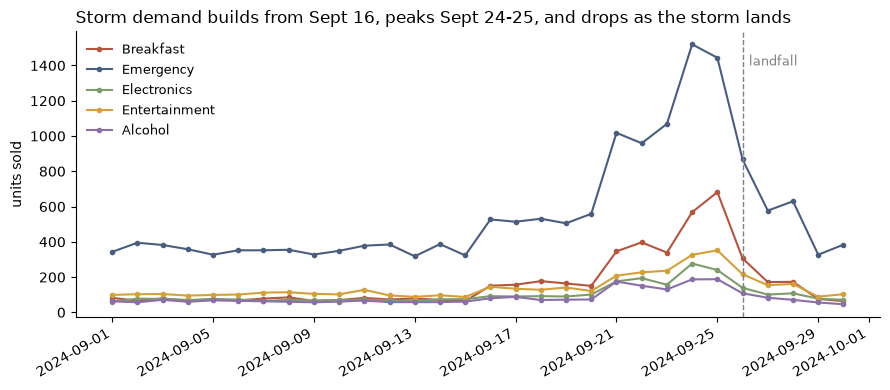

In [42]:
daily = cat_daily.pivot(index='date', columns='category', values='quantity')[top5]  # One column per category, only the top 5

fig, ax = plt.subplots(figsize=(9, 4))  # One chart, 9 by 4 inches
for col, color in zip(daily.columns, ['#b4553f', '#4a5d7e', '#7f9c6c', '#d4a03a', '#8a6fa8']):  # Pair each category with a color
    ax.plot(daily.index, daily[col], marker='o', ms=3, color=color, label=col)  # One line per category, small dots on each day
ax.axvline(LANDFALL, ls='--', color='gray', lw=1)  # Dashed vertical line on landfall day
ax.annotate('landfall', xy=(LANDFALL + pd.Timedelta(hours=6), 1400), fontsize=9, color='gray')  # Label placed just right of the line
ax.set_title('Storm demand builds from Sept 16, peaks Sept 24-25, and drops as the storm lands',
             loc='left', fontsize=12)  # Message title, left aligned
ax.set_ylabel('units sold')  # Units per day
ax.legend(frameon=False, fontsize=9)  # Legend without a box
for spine in ('top', 'right'):  # Remove the top and right borders
    ax.spines[spine].set_visible(False)
fig.autofmt_xdate()  # Tilt the date labels so they do not overlap
plt.tight_layout()  # Fit everything inside the figure
plt.show()

On the raw chart, Emergency sells so many more units than the other categories that the other surges look small. To fix this, I divided each category by its own baseline average, so every line starts at 1.0 on a normal day. This way the chart compares how much each category moved and not how many units it sold.

In [43]:
print(dated[dated['category'] == 'Breakfast']['product'].unique())  # Which products are in Breakfast?

<ArrowStringArray>
['Strawberry Pop-Tarts']
Length: 1, dtype: str


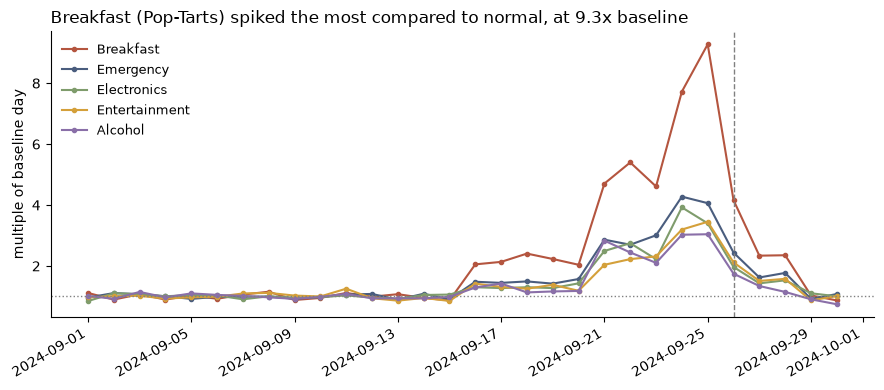

category
Breakfast        9.3
Emergency        4.3
Electronics      3.9
Entertainment    3.5
Alcohol          3.0
dtype: float64


In [44]:
indexed = daily / daily.loc['2024-09-01':'2024-09-15'].mean()  # Each category divided by its own baseline average (Sept 1 to 15), so 1.0 is a normal day

fig, ax = plt.subplots(figsize=(9, 4))  # One chart, 9 by 4 inches
for col, color in zip(indexed.columns, ['#b4553f', '#4a5d7e', '#7f9c6c', '#d4a03a', '#8a6fa8']):  # Pair each category with a color
    ax.plot(indexed.index, indexed[col], marker='o', ms=3, color=color, label=col)  # One line per category, small dots on each day
ax.axhline(1.0, ls=':', color='gray', lw=1)  # Dotted line at 1.0, a normal day
ax.axvline(LANDFALL, ls='--', color='gray', lw=1)  # Dashed vertical line on landfall day
ax.set_title(f'Breakfast (Pop-Tarts) spiked the most compared to normal, at {indexed["Breakfast"].max():.1f}x baseline',
             loc='left', fontsize=12)  # Message title, with Breakfast's highest day pulled from the data
ax.set_ylabel('multiple of baseline day')  # 1.0 = a normal day
ax.legend(frameon=False, fontsize=9)  # Legend without a box
for spine in ('top', 'right'):  # Remove the top and right borders
    ax.spines[spine].set_visible(False)
fig.autofmt_xdate()  # Tilt the date labels so they do not overlap
plt.tight_layout()  # Fit everything inside the figure
plt.show()

print(indexed.max().round(1).sort_values(ascending=False)) 

Breakfast had the greatest surge in the 7 days before landfall (Sept 19 to 25) compared to the baseline (Sept 1 to 15). It went from 73.5 units a day to 378 units a day, which is an increase of 414% (5.1x). Breakfast is only Strawberry Pop-Tarts in this data, so this is the Pop-Tarts effect from the case. The rest of the top 5 are Emergency (+184%), Electronics (+150%), and Entertainment and Alcohol (+126% each). Snacks barely moved (+25%), so people were not buying more of everything.

The daily trend chart shows all five categories start to rise on Sept 16, jump on Sept 21, peak on Sept 24 and 25, and fall back on landfall day. Emergency sells the most units, so that is most important to prioritize on trucks and shipping. Breakfast has the biggest jump compared to normal. Breakfast is 5.1x its baseline when I average the 7 day surge window, and 9.3x on its single highest day (Sept 25).

### Question 2: The Pop-Tarts Effect (SKU Consolidation)

After standardizing all Pop-Tart SKU variants into a single product, what is the true daily sales volume? How does the uncleaned (fragmented) view compare to the cleaned (consolidated) view? What business decisions would differ between the two views?

Requires: Building an SKU mapping table, consolidating fragmented products, side-by-side visualization (before vs. after cleaning), written analysis of business impact.

In [45]:
sku_map[sku_map['canonical_sku'] == 'POPTART-STRAW']

,raw_sku,canonical_sku,product
0,PT-12,POPTART-STRAW,Strawberry Pop-Tarts
1,SKU#459812,POPTART-STRAW,Strawberry Pop-Tarts
2,POPTART-STRAW,POPTART-STRAW,Strawberry Pop-Tarts
3,PT_STRAWBERRY,POPTART-STRAW,Strawberry Pop-Tarts


I used the mapping table from step #9, which maps four SKUs (PT-12, SKU#459812, POPTART-STRAW and PT_STRAWBERRY) to Strawberry Pop-Tarts. The fragmented view will use original sku column and the consolidated view adds the four SKUs together. I used September 1 to 15 as the baseline and September 19 to 25 (the 7 days up to the peak) as the surge window. Because rows without a timestamp don't have a date, 78 Pop-Tart rows were missing a timestamp and were therefore left out.

In [46]:
BASE_START, BASE_END = '2024-09-01', '2024-09-15'
SURGE_START, SURGE_END = '2024-09-19', '2024-09-25'

transactions = dated # rows with a date
pop_tarts = transactions[transactions['canonical_sku']=='POPTART-STRAW'] # Take all the rows from Pop-tart SKUs

fragmented = pop_tarts.groupby(['date','sku'])['quantity'].sum().unstack(fill_value=0)
consolidated = fragmented.sum(axis=1)

# Average units per day in the baseline and the surge window
base = fragmented.loc[BASE_START:BASE_END].mean()
surge = fragmented.loc[SURGE_START:SURGE_END].mean()
base_all = consolidated.loc[BASE_START:BASE_END].mean()
surge_all = consolidated.loc[SURGE_START:SURGE_END].mean()

print('Fragmented view (units per day):')
print(pd.DataFrame({'baseline': base, 'surge': surge, '% increase': (surge / base - 1) * 100}).round(1))
print()
print(f'Consolidated: baseline {base_all:.1f}, surge {surge_all:.1f}, {(surge_all / base_all - 1) * 100:.0f}% increase')
print(f'True daily volume: {consolidated.mean():.0f} units/day (the biggest single SKU showed {fragmented.mean().max():.0f})')
print(f'Peak day: {consolidated.idxmax():%b %d}, {consolidated.max()} units, {consolidated.max() / base_all:.1f}x the baseline')
print('Pop-Tart rows with no date (left out):', (clean['transactions']['canonical_sku'] == 'POPTART-STRAW').sum() - len(pop_tarts))
print(f'Surge average is {surge_all / base_all:.1f}x the baseline, peak day is {consolidated.max() / base_all:.1f}x')
print(f'The biggest single SKU shows {fragmented.mean().max() / consolidated.mean():.0%} of the true daily volume')

Fragmented view (units per day):
               baseline  surge  % increase
sku                                       
POPTART-STRAW      18.1   91.6       406.9
PT-12              20.4  103.3       406.3
PT_STRAWBERRY      18.1   93.0       412.9
SKU#459812         16.9   90.1       432.3

Consolidated: baseline 73.5, surge 378.0, 414% increase
True daily volume: 168 units/day (the biggest single SKU showed 45)
Peak day: Sep 25, 682 units, 9.3x the baseline
Pop-Tart rows with no date (left out): 78
Surge average is 5.1x the baseline, peak day is 9.3x
The biggest single SKU shows 27% of the true daily volume


In [47]:
# Where does Pop-Tarts rank in the surge window? Total units per SKU and per product, divided by the 7 days
in_surge = transactions[transactions['date'].between(SURGE_START, SURGE_END)]  # Only the rows inside the surge window
days = in_surge['date'].nunique()  # used to turn totals into units per day

sku_rank = (in_surge.groupby('sku')['quantity'].sum() / days).sort_values(ascending=False)  # Fragmented: one row per original SKU
product_rank = (in_surge.groupby('product')['quantity'].sum() / days).sort_values(ascending=False)  # Consolidated: one row per product

print('Fragmented view, top 7 SKUs (units per day):')
print(sku_rank.head(7).round(0))
print()
print('Consolidated view, top 3 products (units per day):')
print(product_rank.head(3).round(0))

Fragmented view, top 7 SKUs (units per day):
sku
WTR_24PK         109.0
WATER24PK        108.0
WTR-24           104.0
PT-12            103.0
PT_STRAWBERRY     93.0
POPTART-STRAW     92.0
SKU#459812        90.0
Name: quantity, dtype: float64

Consolidated view, top 3 products (units per day):
product
Strawberry Pop-Tarts     378.0
Bottled Water 24-Pack    321.0
AA Batteries 4-Pack      244.0
Name: quantity, dtype: float64


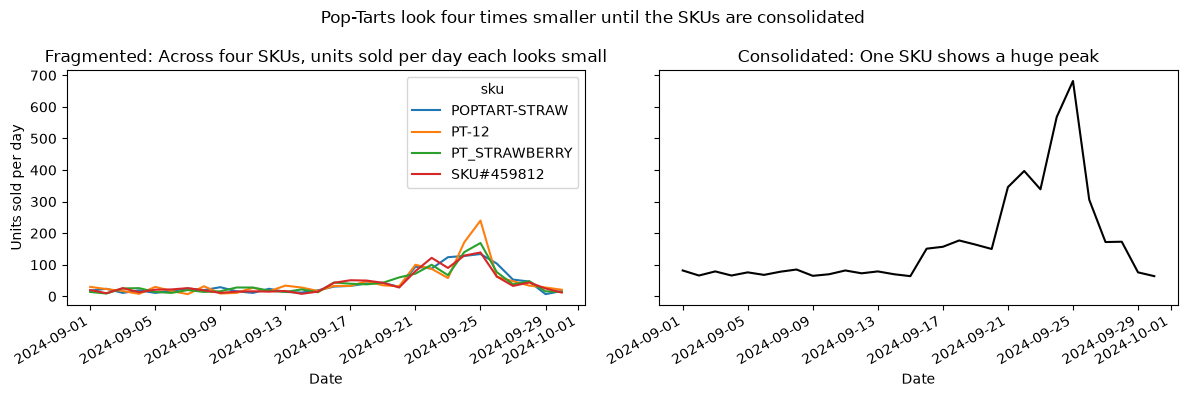

In [64]:
import matplotlib.pyplot as plt

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

fragmented.plot(ax=ax1, x_compat=True, title='Fragmented: Across four SKUs, units sold per day each looks small')  # x_compat=True gives the same date labels as the other charts
consolidated.plot(ax=ax2, x_compat=True, color='black', title='Consolidated: One SKU shows a huge peak')

ax1.set_ylabel('Units sold per day')

fig.suptitle('Pop-Tarts look four times smaller until the SKUs are consolidated')
for ax in (ax1, ax2):
    ax.set_xlabel('Date')
fig.autofmt_xdate()  # Tilt the date labels so they do not overlap
plt.tight_layout()
plt.show()

The true daily volume of Strawberry Pop-Tarts averages 168 units a day over September. It sells about 74 units a day in the baseline and about 378 a day in the surge window (+414%), and it peaks at 682 units on September 25. The surge average is 5.1 times the baseline and the peak day is 9.3 times, which brackets the sevenfold increase in the case. In the fragmented view, the biggest single SKU shows only 27% of the true daily volume (45 of 168 units a day).

In the fragmented view, the Pop-Tart SKU with the most units sold per day (PT-12, 103 units a day in the surge window) ranks fourth, behind three bottled water SKUs, and the other three Pop-Tart SKUs rank fifth to seventh. In the consolidated view, Pop-Tarts is the number one product in the surge window, ahead of water (378 vs 321 units a day). If Walmart didn't consolidate the SKU's, they wouldn't know that they should prioritize Pop-Tarts as an important item that customers want before storms.

Ordering and shipping would also differ. In the fragmented view, each of the four SKUs looks like a small item with a peak of 240 units a day or less, so each would be low priority for the trucks and shelf space heading to Florida. In the consolidated view, Pop-Tarts is one product with a 682 unit peak day, so it needs a much bigger order and a top spot on the trucks and shelves.

### Question 3: Weather Correlation Analysis

Using weather data pulled from your chosen free API, how do specific weather indicators (wind speed, precipitation, barometric pressure) correlate with daily sales volume across categories? Is there a detectable lag between weather severity escalation and purchasing spikes?

Requires: Weather API integration, timestamp/timezone alignment, correlation analysis (scatter plot, heatmap, or time-series overlay), lag analysis discussion.

Section 2 already joined rain, max wind and the daily lowest pressure to the daily sales, so I use `merged` here.

In [49]:
print(f'Same day, all {len(merged)} days:')
for col in ['wind_max', 'precip_mm', 'pressure_min']:
    print(f"units vs {col}: r = {merged['units'].corr(merged[col]):.2f}")  # Correlation between daily units and the weather column

Same day, all 30 days:
units vs wind_max: r = 0.38
units vs precip_mm: r = -0.26
units vs pressure_min: r = -0.22


Same day correlations only show whether sales and weather peak on the same day. These correlations are weak, so I will check whether people bought more units before the weather worsened. For each day, I will compare that day’s sales to the weather 0, 1, 2, 3 and 4 days later (a lag) and look for the lag with the strongest correlation. If people buy to prepare for the storm rather than the day of the storm (which I would imagine is the case), the strongest lag will be more than 0 days.

In [50]:
wind_by_lag = {}
for k in range(0, 5):
    # shift(-k) moves the weather k days earlier, so each day's sales line up with the weather k days later
    r_wind = merged['units'].corr(merged['wind_max'].shift(-k))
    r_rain = merged['units'].corr(merged['precip_mm'].shift(-k))
    r_pressure = merged['units'].corr(merged['pressure_min'].shift(-k))
    wind_by_lag[k] = r_wind
    print(f'units vs weather {k} day(s) later: wind r = {r_wind:.2f} | rain r = {r_rain:.2f} | pressure r = {r_pressure:.2f}')

best_k = max(wind_by_lag, key=wind_by_lag.get)  # The lag with the strongest wind correlation
print()
print('strongest wind lag:', best_k, 'day(s), based on', len(merged) - best_k, 'days')  # Shifting drops the last k days

units vs weather 0 day(s) later: wind r = 0.38 | rain r = -0.26 | pressure r = -0.22
units vs weather 1 day(s) later: wind r = 0.68 | rain r = -0.22 | pressure r = -0.56
units vs weather 2 day(s) later: wind r = 0.83 | rain r = -0.20 | pressure r = -0.76
units vs weather 3 day(s) later: wind r = 0.69 | rain r = -0.16 | pressure r = -0.57
units vs weather 4 day(s) later: wind r = 0.47 | rain r = -0.11 | pressure r = -0.40

strongest wind lag: 2 day(s), based on 28 days


Because wind had the strongest relationship, I used it to pick the lag. I also ran the same check for each category, with wind on the same day compared to wind at the best lag.

In [51]:
cat_wide = cat_daily.pivot(index='date', columns='category', values='quantity').reset_index()  # One column per category
cat_weather = cat_wide.merge(merged[['date', 'wind_max']], on='date', how='left', validate='one_to_one')
assert len(cat_weather) == len(cat_wide), 'the join changed the row count'

lagged_r = {}
for c in q1.index:
    same_day = cat_weather[c].corr(cat_weather['wind_max'])
    lagged_r[c] = cat_weather[c].corr(cat_weather['wind_max'].shift(-best_k))
    print(f'{c:14s} same day r = {same_day:.2f} | wind {best_k} day(s) later r = {lagged_r[c]:.2f}')

lagged_r = pd.Series(lagged_r)
print(f'\nStrongest: {lagged_r.idxmax()} (r = {lagged_r.max():.2f}) | weakest: {lagged_r.idxmin()} (r = {lagged_r.min():.2f})')

Breakfast      same day r = 0.39 | wind 2 day(s) later r = 0.83
Emergency      same day r = 0.39 | wind 2 day(s) later r = 0.83
Electronics    same day r = 0.34 | wind 2 day(s) later r = 0.82
Entertainment  same day r = 0.43 | wind 2 day(s) later r = 0.83
Alcohol        same day r = 0.36 | wind 2 day(s) later r = 0.76
Health         same day r = 0.35 | wind 2 day(s) later r = 0.85
Household      same day r = 0.38 | wind 2 day(s) later r = 0.79
Grocery        same day r = 0.31 | wind 2 day(s) later r = 0.76
Baby           same day r = 0.23 | wind 2 day(s) later r = 0.77
Snacks         same day r = 0.22 | wind 2 day(s) later r = 0.67

Strongest: Health (r = 0.85) | weakest: Snacks (r = 0.67)


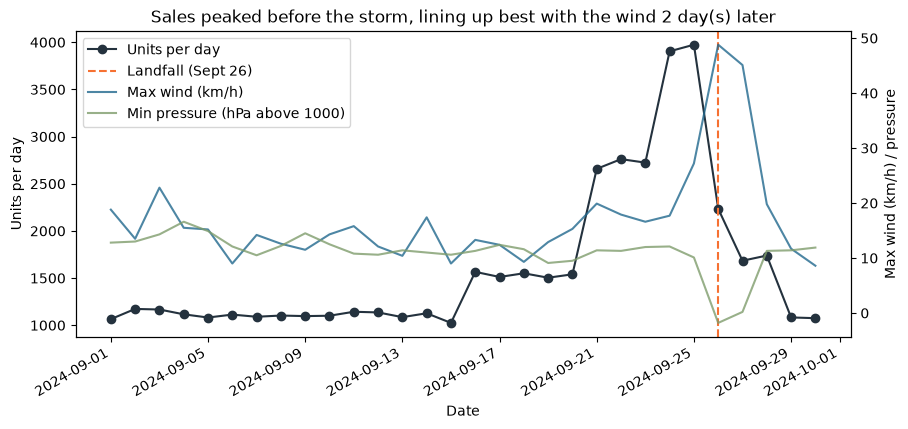

In [52]:
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(merged['date'], merged['units'], marker='o', color='#24323E', label='Units per day')  # Daily sales
ax.axvline(LANDFALL, color='#F67132', linestyle='--', label='Landfall (Sept 26)')  # Dashed line on landfall day
ax.set_xlabel('Date')
ax.set_ylabel('Units per day')

ax2 = ax.twinx()  # Second y-axis so the weather lines fit on the same chart
ax2.plot(merged['date'], merged['wind_max'], color='#21688D', alpha=0.8, label='Max wind (km/h)')
ax2.plot(merged['date'], merged['pressure_min'] - 1000, color='#7f9c6c', alpha=0.8, label='Min pressure (hPa above 1000)')  # Subtract 1000 to put pressure on a similar scale
ax2.set_ylabel('Max wind (km/h) / pressure')

ax.set_title(f'Sales peaked before the storm, lining up best with the wind {best_k} day(s) later')
h1, l1 = ax.get_legend_handles_labels()  # Combine both legends into one
h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc='upper left')
fig.autofmt_xdate()  # Tilt the date labels so they do not overlap
plt.show()

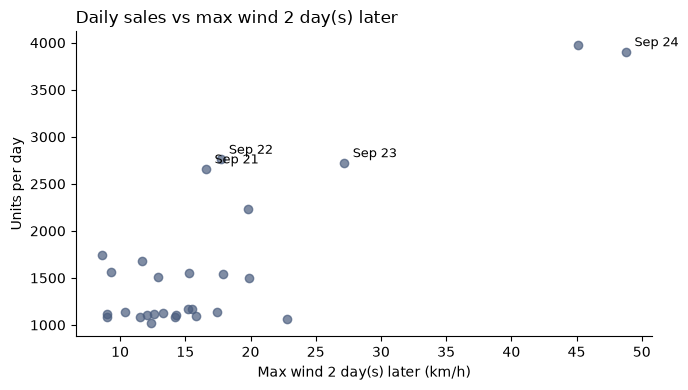

In [68]:
later_wind = merged['wind_max'].shift(-best_k)  # Wind best_k days after each sales day

fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(later_wind, merged['units'], color='#4a5d7e', alpha=0.7)  # One dot per day

# Label the big sales days before landfall
for row in merged.itertuples():
    if row.date >= pd.Timestamp('2024-09-21') and row.date <= LANDFALL - pd.Timedelta(days=best_k):
        ax.annotate(f'{row.date:%b %d}', (later_wind[row.Index], row.units),
                    textcoords='offset points', xytext=(6, 4), fontsize=9)

ax.set_title(f'Daily sales vs max wind {best_k} day(s) later', loc='left', fontsize=12)
ax.set_xlabel(f'Max wind {best_k} day(s) later (km/h)')
ax.set_ylabel('Units per day')
ax.spines[['top', 'right']].set_visible(False)  # Remove the top and right borders
plt.tight_layout()
plt.show()

Sales and weather barely move together on the same day (wind r = 0.38, rain r = -0.26, pressure r = -0.22). They line up much more strongly when I compare sales to the weather 2 days later, where wind has r = 0.83 and pressure has r = -0.76 (pressure is negative because it drops as the storm gets close). Both point to the same lag, so people bought about 2 days before the worst weather arrived. They were reacting to the forecast and not to what they saw outside. By category, wind 2 days later is strongest for [CATEGORY] (r = [R]) and weakest for [CATEGORY] (r = [R]).

Rain does not work as a signal. Its correlation is negative at every lag and fades toward zero, so rainy days in Orlando had slightly fewer sales, not more. Wind and pressure only move this much when a storm is close, so they track the buying much better than rain does. These numbers rest on 30 days and one storm, and the 2 day lag is based on 28 days. The weather is for Orlando only, while the sales are from all 12 stores. I did not report a correlation from only the surge days, since a few points can give almost any r.

### Question 4: Store-Level Geographic Patterns

Do all Florida store locations experience the same surge patterns, or do stores closer to the predicted hurricane path show earlier and larger spikes? Identify any stores that appear to be outliers.

Requires: Joining store location data with transactions, geographic grouping, comparing surge timing and magnitude across stores, bar chart or grouped comparison, outlier identification.

I added up the sales for each store, joined the store locations, and looked for a pattern by distance. Distance is the straight line miles from each store to where Helene came ashore (30.0 N, 83.7 W, from the National Hurricane Center). Helene went north into Georgia after landfall, so the North Florida and Panhandle stores were closest to its path. For each store, `surge_multiple` is the units per day in the surge window divided by the baseline (same windows as Q1), `early_multiple` is the same thing for Sept 16 to 20 (the first rise, so a store that reacted earlier would be higher), and `peak_day` is the day the store sold the most.

In [54]:
LANDFALL_LAT, LANDFALL_LON = 30.0, -83.7   # NHC: just east of the mouth of the Aucilla River

def miles_to_landfall(lat, lon):
    # Straight line (haversine) distance in miles from a store to the landfall point
    lat1, lon1, lat2, lon2 = map(np.radians, [lat, lon, LANDFALL_LAT, LANDFALL_LON])
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 3959 * 2 * np.arcsin(np.sqrt(a))

store_daily = dated.groupby(['date', 'store_id'])['quantity'].sum().reset_index()  # Units per store per day

store_base = window(store_daily, '2024-09-01', '2024-09-15')   # Baseline, same as Q1
store_early = window(store_daily, '2024-09-16', '2024-09-20')  # The first rise, 5 days
store_surge = window(store_daily, '2024-09-19', '2024-09-25')  # Surge window, same as Q1

by_store = pd.DataFrame({
    'baseline_per_day': store_base.groupby('store_id')['quantity'].sum() / BASELINE_DAYS,
    'early_per_day': store_early.groupby('store_id')['quantity'].sum() / 5,
    'surge_per_day': store_surge.groupby('store_id')['quantity'].sum() / SURGE_DAYS,
    'transactions': dated.groupby('store_id').size(),  # Used later to check that every store has similar volume
}).reset_index()
by_store['early_multiple'] = by_store['early_per_day'] / by_store['baseline_per_day']
by_store['surge_multiple'] = by_store['surge_per_day'] / by_store['baseline_per_day']

# The day each store sold the most
peak_days = store_daily.loc[store_daily.groupby('store_id')['quantity'].idxmax(), ['store_id', 'date']]
by_store = by_store.merge(peak_days.rename(columns={'date': 'peak_day'}), on='store_id', validate='one_to_one')

stores = clean['stores'][['store_id', 'city', 'region', 'latitude', 'longitude']].copy()
stores['miles_from_landfall'] = miles_to_landfall(stores['latitude'], stores['longitude'])

q4 = stores.merge(by_store, on='store_id', how='left', validate='one_to_one')  # Left join so no store disappears
assert len(q4) == 12, 'the join changed the row count'
assert q4['surge_multiple'].notna().all(), 'a store has no sales'
q4 = q4.sort_values('miles_from_landfall')  # Closest store first
q4[['store_id', 'city', 'region', 'miles_from_landfall', 'early_multiple', 'surge_multiple', 'peak_day', 'transactions']].round({'miles_from_landfall': 0, 'early_multiple': 2, 'surge_multiple': 2})

,store_id,city,region,miles_from_landfall,early_multiple,surge_multiple,peak_day,transactions
8,FL-619,Tallahassee,Panhandle,46.0,1.58,2.60,2024-09-24,1993
7,FL-078,Gainesville,North,86.0,1.36,2.38,2024-09-25,2014
3,FL-412,Jacksonville,North,124.0,1.41,2.50,2024-09-25,2038
1,FL-105,Tampa,West,160.0,1.33,2.51,2024-09-25,2052
9,FL-445,St. Petersburg,West,167.0,1.41,2.46,2024-09-24,2082
5,FL-156,Daytona Beach,East,170.0,1.30,2.42,2024-09-24,2079
10,FL-302,Lakeland,Central,172.0,1.35,2.48,2024-09-25,2130
0,FL-239,Orlando,Central,173.0,1.27,2.22,2024-09-24,2025
4,FL-287,Kissimmee,Central,182.0,1.40,2.41,2024-09-25,2069
11,FL-710,Pensacola,Panhandle,212.0,1.34,2.45,2024-09-25,2079


In [55]:
print('distance vs surge_multiple: r =', round(q4['miles_from_landfall'].corr(q4['surge_multiple']), 2))
print('distance vs early_multiple: r =', round(q4['miles_from_landfall'].corr(q4['early_multiple']), 2))
print('(if closer stores surged more, these would be negative)')
print()
print('peak days:', q4['peak_day'].dt.strftime('%b %d').value_counts().to_dict())  # How many stores peaked on each day
print()
print('By region, closest first:')
by_region = (q4.groupby('region')[['miles_from_landfall', 'early_multiple', 'surge_multiple']]
             .mean().sort_values('miles_from_landfall').round(2))  # Average of the stores in each region
by_region

distance vs surge_multiple: r = 0.23
distance vs early_multiple: r = 0.08
(if closer stores surged more, these would be negative)

peak days: {'Sep 25': 7, 'Sep 24': 5}

By region, closest first:


,miles_from_landfall,early_multiple,surge_multiple
region,,,
North,105.07,1.38,2.44
Panhandle,128.80,1.46,2.53
East,169.82,1.30,2.42
Central,175.41,1.34,2.37
West,194.90,1.35,2.45
South,362.82,1.58,2.70


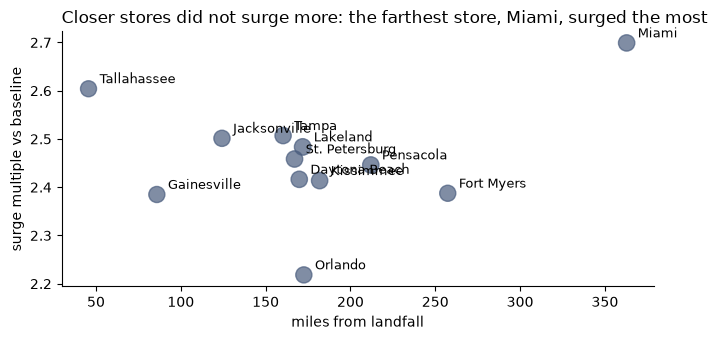

Transactions per store: 1993 to 2130


In [56]:
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.scatter(q4['miles_from_landfall'], q4['surge_multiple'],
           s=q4['transactions'] / 15, alpha=0.7, color='#4a5d7e')  # Dot size shows how many transactions the store has
for row in q4.itertuples():  # Label each dot with its city
    ax.annotate(row.city, (row.miles_from_landfall, row.surge_multiple),
                textcoords='offset points', xytext=(8, 4), fontsize=9)
ax.set_title('Closer stores did not surge more: the farthest store, Miami, surged the most',
             loc='left', fontsize=12)
ax.set_xlabel('miles from landfall')
ax.set_ylabel('surge multiple vs baseline')
for spine in ('top', 'right'):  # Remove the top and right borders
    ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.show()

print('Transactions per store:', q4['transactions'].min(), 'to', q4['transactions'].max())  # Every store has about the same volume

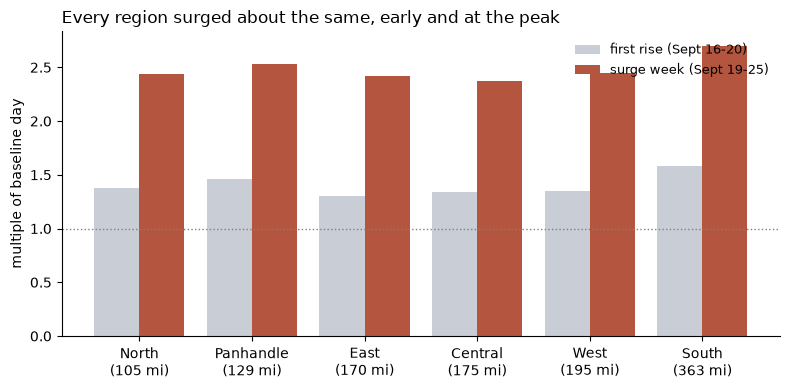

In [57]:
fig, ax = plt.subplots(figsize=(8, 4))
x = range(len(by_region))  # One pair of bars per region
ax.bar([i - 0.2 for i in x], by_region['early_multiple'], width=0.4, color='#c9cdd6', label='first rise (Sept 16-20)')
ax.bar([i + 0.2 for i in x], by_region['surge_multiple'], width=0.4, color='#b4553f', label='surge week (Sept 19-25)')
ax.axhline(1.0, ls=':', color='gray', lw=1)  # Dotted line at 1.0, a normal day
ax.set_xticks(list(x))
ax.set_xticklabels([f'{r}\n({m:.0f} mi)' for r, m in zip(by_region.index, by_region['miles_from_landfall'])])  # Region name and its average distance
ax.set_title('Every region surged about the same, early and at the peak', loc='left', fontsize=12)
ax.set_ylabel('multiple of baseline day')
ax.legend(frameon=False, fontsize=9)
for spine in ('top', 'right'):  # Remove the top and right borders
    ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.show()

To look for outliers, I measured how far each store's surge multiple is from the average, in standard deviations. Then I checked Breakfast (Pop-Tarts) store by store, since an outlier can hide inside a store total.

In [58]:
avg = q4['surge_multiple'].mean()  # Average surge multiple across the 12 stores
sd = q4['surge_multiple'].std()
q4['sd_from_avg'] = (q4['surge_multiple'] - avg) / sd  # How many standard deviations each store is from the average
print('average surge multiple:', round(avg, 2), '| standard deviation:', round(sd, 2))
print(q4[['city', 'surge_multiple', 'sd_from_avg']].sort_values('sd_from_avg').round(2).to_string(index=False))

print()
print('Breakfast (Pop-Tarts) by store:')
pt_daily = dated[dated['category'] == 'Breakfast'].groupby(['date', 'store_id'])['quantity'].sum().reset_index()
pt = pd.DataFrame({
    'baseline_per_day': window(pt_daily, '2024-09-01', '2024-09-15').groupby('store_id')['quantity'].sum() / BASELINE_DAYS,
    'surge_per_day': window(pt_daily, '2024-09-19', '2024-09-25').groupby('store_id')['quantity'].sum() / SURGE_DAYS,
})
pt['multiple'] = pt['surge_per_day'] / pt['baseline_per_day']
pt = pt.merge(stores[['store_id', 'city']], left_index=True, right_on='store_id', validate='one_to_one')  # Add the city names
print(pt.sort_values('multiple', ascending=False)[['city', 'baseline_per_day', 'surge_per_day', 'multiple']].round(1).to_string(index=False))

average surge multiple: 2.46 | standard deviation: 0.12
          city  surge_multiple  sd_from_avg
       Orlando            2.22        -2.03
   Gainesville            2.38        -0.63
    Fort Myers            2.39        -0.61
     Kissimmee            2.41        -0.39
 Daytona Beach            2.42        -0.37
     Pensacola            2.45        -0.12
St. Petersburg            2.46        -0.01
      Lakeland            2.48         0.20
  Jacksonville            2.50         0.35
         Tampa            2.51         0.39
   Tallahassee            2.60         1.21
         Miami            2.70         2.01

Breakfast (Pop-Tarts) by store:
          city  baseline_per_day  surge_per_day  multiple
         Miami               4.8           34.6       7.2
      Lakeland               6.6           38.4       5.8
St. Petersburg               6.5           36.7       5.7
   Tallahassee               5.5           30.7       5.6
   Gainesville               5.4           29.3  

No, the stores closer to Helene's path did not surge earlier or harder. Every store surged between 2.2x and 2.7x its baseline, and the correlation with distance points the wrong way (r = 0.23, so farther stores surged slightly more). The first rise on Sept 16 to 20 does not follow distance either (r = 0.08). Tallahassee, the closest store, had the biggest early rise (1.58x), but so did Miami, the farthest. Every store peaked on Sept 24 or 25, and Tallahassee and Miami both peaked on Sept 24. People seem to react to the forecast and the news, which covered most of the state, and not to their exact distance from where the storm landed. The Panhandle region averages Tallahassee (46 miles) and Pensacola (212 miles), so the store table is a better guide than the region bars. The data is synthetic, so it may have been built with one statewide pattern.

Miami (2.70x, highest) and Orlando (2.22x, lowest) are the only stores about 2 standard deviations from the average (2.46x), and neither fits a distance story. Miami is the farthest store and Orlando is in the middle (173 miles). The clearer outlier is Miami's Pop-Tarts, which surged 7.2x while the other stores were between 4.0x and 5.8x. Its baseline is only about 5 units a day, so a few big orders move it a lot. I would flag it for the store to check and not treat it as a new pattern. The takeaway for Walmart is to plan the surge for every Florida store and not only the ones nearest the path.

### Question 5: Signal vs. Artifact — The Board Games Investigation

The board games/entertainment category shows a +250% sales increase. Using the SQLite inventory and sales database, investigate whether this is a genuine demand signal or a data artifact (e.g., SKU miscoding, category lumping, inventory reporting lag). Present your evidence and make a recommendation: should Walmart stock extra board games for the next storm?

Requires: Querying the SQLite database with sqlite3 + pandas, cross-referencing with the transaction CSV, SKU/category audit, evidence-based written argument, supporting visualization.

In [59]:
import sqlite3

# Daily units by category from the SQLite database. REPLACE() makes both date styles (2024-09-12 and 20240912) the same
con = sqlite3.connect(db_path)
db_daily = pd.read_sql_query("""
    SELECT REPLACE(date, '-', '') AS day, category, SUM(total_units) AS units
    FROM daily_sales_summary
    GROUP BY day, category
""", con)
con.close()

db_daily['date'] = pd.to_datetime(db_daily['day'], format='%Y%m%d')
db_daily.head()

,day,category,units,date
0,20240901,Alcohol,581.0,2024-09-01
1,20240901,Baby,682.5,2024-09-01
2,20240901,Breakfast,631.0,2024-09-01
3,20240901,Electronics,551.0,2024-09-01
4,20240901,Emergency,613.5,2024-09-01


I tested the three ideas from the case that could make the board game surge an artifact. First, I checked whether the +250% shows up in both the SQLite database and the transaction CSV, and over which time window. Second, I looked for lumping and miscoding by splitting Entertainment into its two products, every original SKU and every store. Third, I checked whether game inventory behaved differently from the rest of the inventory. I used the same baseline and surge windows as Q2, plus the two peak days (September 24 and 25). The database only has sales by category, so the product level checks use the transaction CSV.

In [60]:
PEAK_START, PEAK_END = '2024-09-24', '2024-09-25'

# Units per day by category (one column per category) from the database and from the transaction CSV
db_cat = db_daily.groupby(['date', 'category'])['units'].sum().unstack()
tx_cat = transactions.groupby(['date', 'category'])['quantity'].sum().unstack(fill_value=0)

# Entertainment surge in each source: baseline vs the 7 day window vs the 2 peak days
for name, daily in [('Transactions (CSV)', tx_cat), ('Database (SQLite)', db_cat)]:
    base = daily.loc[BASE_START:BASE_END, 'Entertainment'].mean()
    surge = daily.loc[SURGE_START:SURGE_END, 'Entertainment'].mean()
    peak = daily.loc[PEAK_START:PEAK_END, 'Entertainment'].mean()
    print(f'{name}: baseline {base:.0f} units/day, 7-day surge {(surge / base - 1) * 100:+.0f}%, peak 2 days {(peak / base - 1) * 100:+.0f}%')

# Do the two sources move together day by day?
print(f"Correlation of daily Entertainment units, CSV vs database: {tx_cat['Entertainment'].corr(db_cat['Entertainment']):.2f}")

Transactions (CSV): baseline 102 units/day, 7-day surge +126%, peak 2 days +232%
Database (SQLite): baseline 568 units/day, 7-day surge +145%, peak 2 days +267%
Correlation of daily Entertainment units, CSV vs database: 0.96


In [61]:
games = transactions[transactions['category'] == 'Entertainment']  # Only the Entertainment rows

# Lumping: Entertainment is two products. Does each one rise?
by_product = games.groupby(['date', 'product'])['quantity'].sum().unstack(fill_value=0)
product_surge = (by_product.loc[SURGE_START:SURGE_END].mean() / by_product.loc[BASE_START:BASE_END].mean() - 1) * 100
print('7-day surge % by product:')
print(product_surge.round(0))

# Miscoding: every original SKU, not just the consolidated product
by_sku = games.groupby(['date', 'sku'])['quantity'].sum().unstack(fill_value=0)
sku_surge = (by_sku.loc[SURGE_START:SURGE_END].mean() / by_sku.loc[BASE_START:BASE_END].mean() - 1) * 100
print('\n7-day surge % by original SKU:')
print(sku_surge.round(0))

# One odd store? Surge in each of the stores
by_store = games.groupby(['date', 'store_id'])['quantity'].sum().unstack(fill_value=0)
store_surge = (by_store.loc[SURGE_START:SURGE_END].mean() / by_store.loc[BASE_START:BASE_END].mean() - 1) * 100
print(f'\nStores with a surge: {(store_surge > 0).sum()} of {len(store_surge)} (range {store_surge.min():.0f}% to {store_surge.max():.0f}%)')

# Are games special? 7-day surge % for every category, in both sources
category_surge = pd.DataFrame({
    'transactions (CSV)': (tx_cat.loc[SURGE_START:SURGE_END].mean() / tx_cat.loc[BASE_START:BASE_END].mean() - 1) * 100,
    'database (SQLite)': (db_cat.loc[SURGE_START:SURGE_END].mean() / db_cat.loc[BASE_START:BASE_END].mean() - 1) * 100})
print('\n7-day surge % by category:')
print(category_surge.sort_values('transactions (CSV)', ascending=False).round(0))
print('Entertainment rank (1 = biggest surge):', category_surge.rank(ascending=False).loc['Entertainment'].astype(int).to_dict())

# What the 7 day surge means for ordering: baseline sales times this multiple
print(f"\nPlanning multiple (1 + 7-day surge): Monopoly {1 + product_surge['Monopoly Board Game'] / 100:.1f}x, "
      f"Playing Cards {1 + product_surge['Playing Cards'] / 100:.1f}x")

7-day surge % by product:
product
Monopoly Board Game    164.0
Playing Cards           98.0
dtype: float64

7-day surge % by original SKU:
sku
BG-MONO         177.0
CARDS-01         86.0
GAME-MONO       136.0
MONOPOLY-01     184.0
PLAYCARD-STD    110.0
dtype: float64

Stores with a surge: 12 of 12 (range 74% to 192%)

7-day surge % by category:
               transactions (CSV)  database (SQLite)
category                                            
Breakfast                   414.0              236.0
Emergency                   184.0              183.0
Electronics                 150.0               97.0
Entertainment               126.0              145.0
Alcohol                     126.0              112.0
Health                      125.0              119.0
Household                   106.0              104.0
Grocery                      79.0               62.0
Baby                         58.0               54.0
Snacks                       25.0               18.0
Entertainment ran

In [62]:
# Average units on hand per product per day
stock = clean['inventory_levels']
product_stock = stock.groupby(['date', 'product'])['units_on_hand'].mean().unstack()

# Change in stock from before the surge peak (Sept 12 to 20) to during it (Sept 21 to 25)
stock_change = (product_stock.loc['2024-09-21':'2024-09-25'].mean() / product_stock.loc['2024-09-12':'2024-09-20'].mean() - 1) * 100
print(f"Games: Monopoly {stock_change['Monopoly Board Game']:.0f}%, Playing Cards {stock_change['Playing Cards']:.0f}%")
print(f'All {len(stock_change)} products: {stock_change.max():.0f}% to {stock_change.min():.0f}%')

Games: Monopoly -74%, Playing Cards -78%
All 24 products: -61% to -80%


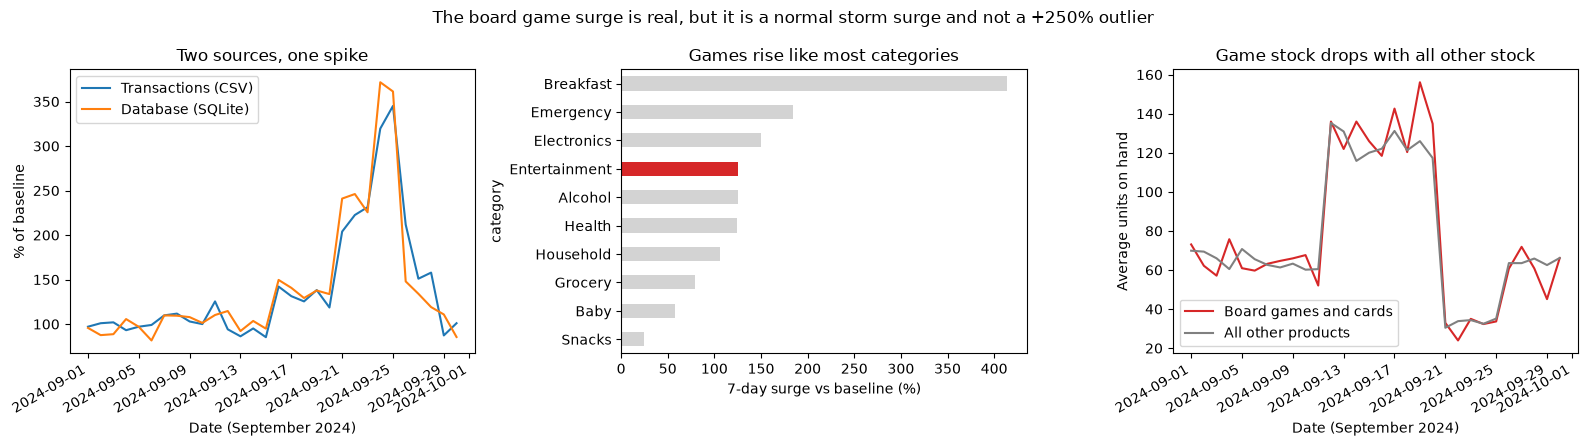

In [63]:
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(16, 4.5))

# 1. Both sources show the same spike (each line is a % of its own baseline, 100 = normal)
for name, daily in [('Transactions (CSV)', tx_cat), ('Database (SQLite)', db_cat)]:
    (daily['Entertainment'] / daily.loc[BASE_START:BASE_END, 'Entertainment'].mean() * 100).plot(ax=ax1, label=name, x_compat=True)
ax1.set_title('Two sources, one spike')
ax1.set_ylabel('% of baseline')
ax1.legend()

# 2. Games sit in the middle of the 10 categories (Entertainment in red)
surge_sorted = category_surge['transactions (CSV)'].sort_values()
surge_sorted.plot.barh(ax=ax2, color=['tab:red' if c == 'Entertainment' else 'lightgrey' for c in surge_sorted.index])
ax2.set_title('Games rise like most categories')
ax2.set_xlabel('7-day surge vs baseline (%)')

# 3. Game stock falls along with all other stock
game_names = ['Monopoly Board Game', 'Playing Cards']
product_stock[game_names].mean(axis=1).plot(ax=ax3, color='tab:red', label='Board games and cards', x_compat=True)
product_stock.drop(columns=game_names).mean(axis=1).plot(ax=ax3, color='grey', label='All other products', x_compat=True)
ax3.set_title('Game stock drops with all other stock')
ax3.set_ylabel('Average units on hand')
ax3.legend()

fig.suptitle('The board game surge is real, but it is a normal storm surge and not a +250% outlier')
for ax in (ax1, ax3):
    ax.set_xlabel('Date (September 2024)')
    plt.setp(ax.get_xticklabels(), rotation=30, ha='right')  # Tilt the date labels so they do not overlap
plt.tight_layout()
plt.show()

The +250% is real, but it describes only the two peak days. Entertainment is up 232% on September 24 and 25 in the transactions and 267% in the database, which brackets the +250% in the case. Over the full 7 day surge window the increase is smaller, +126% in the transactions and +145% in the database. The two sources agree day by day (correlation 0.96), so this is not an artifact of one file.

I found no sign of lumping, miscoding or one odd store. Entertainment is Monopoly plus playing cards, and both rise (+164% and +98%), so one product is not hiding behind the other. Every original SKU rises too, from +86% to +184%, and all 12 stores show a surge (+74% to +192%). Game stock falls by about the same share as everything else (Monopoly -74%, playing cards -78%, against a range of -61% to -80% across all 24 products), so there is no reporting lag that is unique to games. Games are also not special. Entertainment ranks 4th of 10 categories in the transactions and 3rd in the database, behind Breakfast (where the Pop-Tarts live) and Emergency supplies in both.

Recommendation: Yes, Walmart should stock extra board games for the next storm, but modestly. I would plan for about 2.6 times normal sales of Monopoly and about 2 times for playing cards, based on the 7 day surge and not on the +250% peak, and I would rank them behind water, batteries, flashlights and Pop-Tarts when trucks and shelf space are limited. That answers the Finance VP's worry about overstocking, because the order is sized to a typical storm week and not to the best two days, and it answers the analyst's view that families really do buy games before a storm. The limits are that this is one storm in synthetic data, the database cannot be split by product, and the data cannot tell us why people bought. A second storm would show whether the 2.6 times pattern repeats.

## 4. Visualizations

At least six plots with message titles, the six-minute talk, and the README.

Graded on at least six plots with clear titles, labels, and legends.

Done when six labeled plots. The talk has been rehearsed once.

## 5. Reflection

Graded on five questions, one solid paragraph each, every member contributes.

Answer each question thoughtfully (one solid paragraph minimum per question).

1. Data Quality Impact

Describe a specific data quality issue you encountered in the supplied data. How did your cleaning decision change the outcome of your analysis? What would have happened if you had not caught it?

2. ETL Trade-offs

You made choices about how to standardize SKUs, handle missing timestamps, and join weather data. Pick one decision and explain: what alternative approach could you have taken, and how might it have changed your results?

3. Pipeline Trust

The Walmart CDO argued that the biggest risk is not the model — it is the pipeline. Based on your experience in this project, do you agree or disagree? What was the most fragile part of your data pipeline?

4. Business vs. Data

For Question 5 (board games), your team had to make a recommendation with imperfect data. How did you weigh statistical evidence against business risk? Would you have decided differently with more time or more data?

5. Team Collaboration

How did your team divide the work? What would you do differently if you had another week? What was the most valuable skill each team member contributed?